In [1]:
import copy
import sys
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from scipy.signal import find_peaks
from scipy.stats import rankdata
warnings.filterwarnings("ignore", message="IProgress not found")
sys.path.append(str(Path.cwd().parent))
from src.architectures import ArchitectureFactory
from src.config import LEAD_NAMES, SAMPLING_RATE, SUPERCLASSES, ProjectPaths, Runtime, TrainingConfig
from src.data import BatchStream, FoldNormalizer, GpuCohort, NormalizationStore
from src.metrics import MultilabelScores, ThresholdSearch

In [2]:
PROJECT_ROOT = Path.cwd().parent
ARCHITECTURE = "cnn1d"
RUN_NAME = "cnn1d__crop"
REGISTERED_NAME = "ptbxl-superclass-cnn1d-crop"
MODEL_VERSION = 1
FINAL_PARTITION = "final"
RANDOM_SEED = 42
CERTAIN_LIKELIHOOD = 100
TOP_RECORD_COUNT = 100
MULTI_LABEL_CLASSES = ("MI", "CD")
ERROR_CLASS = "HYP"
METHODS = ("saliency", "integrated_gradients", "grad_cam")
LEAD_RESOLVED_METHODS = ("saliency", "integrated_gradients")
ATTRIBUTION_BATCH_SIZE = 64
INTEGRATION_STEPS = 64
SIGNAL_BASELINE = 0.0
METADATA_BASELINE = (0.0, 0.5)
METADATA_NAMES = ("age", "sex")
RANDOMIZATION_STAGES = ("head", "head + last block", "all layers")
SANITY_SIMILARITY_LIMIT = 0.5
DELETION_PATCH = 16
DELETION_FRACTIONS = (0.0, 0.05, 0.1, 0.2, 0.3, 0.5)
ENERGY_WINDOW = 8
MIN_BEAT_DISTANCE = 30
PEAK_HEIGHT_RATIO = 0.35
PEAK_HEIGHT_PERCENTILE = 95
BEAT_BEFORE = 30
BEAT_AFTER = 50
BEAT_LENGTH = BEAT_BEFORE + BEAT_AFTER
BEAT_SEGMENTS = {"P-PR": (0, 24), "QRS": (24, 36), "ST-T": (36, 80)}
TEMPLATE_LEADS = ("II", "V5")
RELEVANCE_SMOOTHING = 5
RELEVANCE_PERCENTILE = 99.5
BASE_FIGURE_SIZE = (12, 5)
WIDE_FIGURE_SIZE = (18, 6)
PANEL_FIGURE_SIZE = (20, 4.5)
TALL_PANEL_FIGURE_SIZE = (20, 6)
SQUARE_FIGURE_SIZE = (9, 7)
LEAD_FIGURE_SIZE = (16, 14)
LEAD_GRID = (6, 2)
FIGURE_DPI = 110
PRIMARY_COLOR = "#2E5E8C"
SECONDARY_COLOR = "#E07A5F"
NEUTRAL_COLOR = "#9AA5B1"
SEQUENTIAL_CMAP = "Blues"
SUPERCLASS_COLORS = {"NORM": "#4C9F70", "MI": "#D1495B", "STTC": "#EDAE49", "CD": "#00798C", "HYP": "#7B5EA7"}
METHOD_COLORS = {"saliency": PRIMARY_COLOR, "integrated_gradients": SECONDARY_COLOR, "grad_cam": NEUTRAL_COLOR}

In [3]:
class PlotTheme:
    @staticmethod
    def apply():
        sns.set_theme(style="whitegrid", context="notebook")
        plt.rcParams.update({
            "figure.figsize": BASE_FIGURE_SIZE,
            "figure.dpi": FIGURE_DPI,
            "axes.titlesize": 13,
            "axes.titleweight": "bold",
            "axes.labelsize": 11,
            "axes.spines.top": False,
            "axes.spines.right": False,
            "legend.frameon": False
        })

    @staticmethod
    def class_colors(labels):
        return [SUPERCLASS_COLORS.get(label, NEUTRAL_COLOR) for label in labels]

    @staticmethod
    def figure(nrows=1, ncols=1, size=BASE_FIGURE_SIZE, sharex=False, sharey=False):
        return plt.subplots(nrows, ncols, figsize=size, sharex=sharex, sharey=sharey, constrained_layout=True)

    @staticmethod
    def decorate(ax, title, xlabel=None, ylabel=None):
        ax.set_title(title)
        ax.set_xlabel(xlabel or "")
        ax.set_ylabel(ylabel or "")

PlotTheme.apply()

In [4]:
class ModelRepository:
    def __init__(self, paths, config):
        self.paths = paths
        self.config = config
        self.run_directory = next((paths.run_checkpoints_dir / RUN_NAME).iterdir())

    def load(self, path):
        checkpoint = torch.load(path, map_location=Runtime.device, weights_only=True)
        model, _ = ArchitectureFactory.build(ARCHITECTURE, self.config.head_dropout)
        model.load_state_dict(checkpoint["state_dict"])
        return model.to(Runtime.device).eval()

    def final(self):
        return self.load(self.paths.registry_checkpoints_dir / REGISTERED_NAME / f"v{MODEL_VERSION}.pt")

    def fold(self, fold):
        return self.load(self.run_directory / f"fold_{fold}.pt")

class FullSignalPredictions:
    def __init__(self, cohort, normalization, repository, config):
        self.cohort = cohort
        self.normalization = normalization
        self.repository = repository
        self.config = config

    @torch.no_grad()
    def predict(self, model, rows, normalizer):
        batches = [
            (torch.sigmoid(model(signals, metadata)).cpu(), labels.cpu().long())
            for signals, metadata, labels in BatchStream(self.cohort, rows, normalizer, self.config.batch_size)
        ]
        probabilities, labels = zip(*batches)
        return torch.cat(labels), torch.cat(probabilities)

    def normalizer(self, partition):
        return FoldNormalizer(self.normalization.statistics(partition))

    def out_of_fold(self):
        folds = [self.predict(self.repository.fold(fold), self.cohort.fold_rows([fold]), self.normalizer(f"cv_{fold}")) for fold in self.cohort.plan.folds]
        labels, probabilities = zip(*folds)
        return torch.cat(labels), torch.cat(probabilities)

    def test(self):
        return self.predict(self.repository.final(), self.cohort.test_rows(), self.normalizer(FINAL_PARTITION))

class RecordSelector:
    def __init__(self, records, labels, probabilities, thresholds):
        self.records = records
        self.labels = pd.DataFrame(labels.numpy().astype(bool), index=records.index, columns=SUPERCLASSES)
        self.probabilities = pd.DataFrame(probabilities.numpy(), index=records.index, columns=SUPERCLASSES)
        self.predicted = pd.DataFrame((probabilities >= thresholds).numpy(), index=records.index, columns=SUPERCLASSES)
        self.validated = records["validated_by_human"].to_numpy()

    def true_positive(self, superclass):
        return self.labels[superclass] & self.predicted[superclass] & self.validated

    def missed(self, superclass):
        return self.labels[superclass].index[self.labels[superclass] & ~self.predicted[superclass] & self.validated].to_numpy()

    def top_true_positives(self, superclass):
        return self.probabilities.loc[self.true_positive(superclass), superclass].nlargest(TOP_RECORD_COUNT).index.to_numpy()

    def single_label_example(self, superclass):
        single_label = self.labels.sum(axis=1).eq(1)
        certain = self.records[f"likelihood_{superclass}"].ge(CERTAIN_LIKELIHOOD)
        return int(self.probabilities.loc[self.true_positive(superclass) & single_label & certain, superclass].idxmax())

    def multi_label_example(self, superclasses):
        expected = pd.Series(self.labels.columns.isin(superclasses), index=self.labels.columns)
        correct = self.labels.eq(expected).all(axis=1) & self.predicted.eq(expected).all(axis=1) & self.validated
        return int(self.probabilities.loc[correct, list(superclasses)].min(axis=1).idxmax())

    def counts(self):
        return pd.DataFrame({
            "positive": self.labels.sum(),
            "validated_true_positive": [self.true_positive(superclass).sum() for superclass in SUPERCLASSES],
            "validated_missed": [len(self.missed(superclass)) for superclass in SUPERCLASSES],
            "analysed": [len(self.top_true_positives(superclass)) for superclass in SUPERCLASSES]
        })

In [5]:
class Attribution:
    def __init__(self, model, cohort, normalizer):
        self.model = model
        self.cohort = cohort
        self.normalizer = normalizer
        self.feature_layer = model.backbone.layers[-1][0]
        self.signal_baseline = torch.tensor(SIGNAL_BASELINE, device=Runtime.device)
        self.metadata_baseline = torch.tensor(METADATA_BASELINE, device=Runtime.device)

    def inputs(self, rows):
        return self.normalizer.signals(self.cohort.signals[rows]), self.normalizer.metadata(self.cohort.metadata[rows])

    def gradients(self, signals, metadata, class_index):
        signals = signals.clone().requires_grad_(True)
        metadata = metadata.clone().requires_grad_(True)
        return torch.autograd.grad(self.model(signals, metadata)[:, class_index].sum(), (signals, metadata))

    def saliency(self, signals, metadata, class_index):
        return self.gradients(signals, metadata, class_index)[0].abs()

    def integrated(self, signals, metadata, class_index):
        signal_delta = signals - self.signal_baseline
        metadata_delta = metadata - self.metadata_baseline
        signal_total, metadata_total = torch.zeros_like(signals), torch.zeros_like(metadata)
        for step in range(INTEGRATION_STEPS):
            alpha = (step + 0.5) / INTEGRATION_STEPS
            signal_gradient, metadata_gradient = self.gradients(self.signal_baseline + alpha * signal_delta, self.metadata_baseline + alpha * metadata_delta, class_index)
            signal_total += signal_gradient
            metadata_total += metadata_gradient
        return signal_delta * signal_total / INTEGRATION_STEPS, metadata_delta * metadata_total / INTEGRATION_STEPS

    def integrated_gradients(self, signals, metadata, class_index):
        return self.integrated(signals, metadata, class_index)[0].clamp(min=0)

    def grad_cam(self, signals, metadata, class_index):
        activations = []
        handle = self.feature_layer.register_forward_hook(lambda _, __, output: activations.append(output))
        score = self.model(signals, metadata)[:, class_index].sum()
        handle.remove()
        gradients = torch.autograd.grad(score, activations[0])[0]
        cam = (gradients.mean(dim=2, keepdim=True) * activations[0]).sum(dim=1, keepdim=True).relu()
        return torch.nn.functional.interpolate(cam, size=signals.shape[-1], mode="linear").expand_as(signals)

    def batches(self, rows):
        return [self.inputs(rows[start:start + ATTRIBUTION_BATCH_SIZE]) for start in range(0, len(rows), ATTRIBUTION_BATCH_SIZE)]

    def relevance(self, method, rows, class_index):
        return torch.cat([getattr(self, method)(signals, metadata, class_index).detach() for signals, metadata in self.batches(rows)])

    def signed_integrated(self, rows, class_index):
        signal_parts, metadata_parts = zip(*[self.integrated(signals, metadata, class_index) for signals, metadata in self.batches(rows)])
        return torch.cat(signal_parts), torch.cat(metadata_parts)

    def completeness_gap(self, rows, class_index):
        signal_attribution, metadata_attribution = self.signed_integrated(rows, class_index)
        total = signal_attribution.sum(dim=(1, 2)) + metadata_attribution.sum(dim=1)
        signals, metadata = self.inputs(rows)
        with torch.no_grad():
            baseline_logit = self.model(torch.full_like(signals, SIGNAL_BASELINE), self.metadata_baseline.expand_as(metadata))[:, class_index]
            return (total - self.model(signals, metadata)[:, class_index] + baseline_logit).abs().mean().item()

class SanityCheck:
    def __init__(self, model, cohort, normalizer):
        self.model = model
        self.cohort = cohort
        self.normalizer = normalizer

    @staticmethod
    def reset(block):
        for module in block.modules():
            if hasattr(module, "reset_parameters"):
                module.reset_parameters()

    def randomized_models(self):
        Runtime.seed_everything(RANDOM_SEED)
        model = copy.deepcopy(self.model)
        for stage, block in zip(RANDOMIZATION_STAGES, (model.head, model.backbone.layers[-1], model.backbone.layers[:-1])):
            self.reset(block)
            yield stage, Attribution(model, self.cohort, self.normalizer)

    @staticmethod
    def rank_similarity(first, second):
        first_ranks = rankdata(first.flatten(1).cpu().numpy(), axis=1)
        second_ranks = rankdata(second.flatten(1).cpu().numpy(), axis=1)
        first_ranks -= first_ranks.mean(axis=1, keepdims=True)
        second_ranks -= second_ranks.mean(axis=1, keepdims=True)
        norms = np.linalg.norm(first_ranks, axis=1) * np.linalg.norm(second_ranks, axis=1)
        return float(np.mean(np.divide((first_ranks * second_ranks).sum(axis=1), norms, out=np.zeros(len(norms)), where=norms > 0)))

    def similarity_table(self, attribution, selected_rows):
        table = {}
        for stage, randomized in self.randomized_models():
            table[stage] = {
                method: np.mean([
                    self.rank_similarity(attribution.relevance(method, rows, class_index), randomized.relevance(method, rows, class_index))
                    for class_index, rows in enumerate(selected_rows.values())
                ])
                for method in METHODS
            }
        return pd.DataFrame(table)

class DeletionTest:
    def __init__(self, model):
        self.model = model

    @torch.no_grad()
    def probability(self, signals, metadata, class_index):
        return torch.sigmoid(self.model(signals, metadata)[:, class_index]).mean().item()

    @staticmethod
    def patches(values):
        return values[..., :values.shape[-1] // DELETION_PATCH * DELETION_PATCH].unflatten(-1, (-1, DELETION_PATCH))

    def perturbed(self, signals, relevance, fraction, descending):
        patches = self.patches(signals)
        scores = self.patches(relevance).sum(dim=-1).flatten(1)
        chosen = scores.argsort(dim=1, descending=descending, stable=True)[:, :int(fraction * scores.shape[1])]
        mask = torch.zeros_like(scores, dtype=torch.bool).scatter_(1, chosen, True).view(*patches.shape[:3], 1)
        filled = torch.where(mask, patches.mean(dim=-1, keepdim=True), patches).flatten(-2)
        return torch.cat([filled, signals[..., filled.shape[-1]:]], dim=-1)

    def curve(self, signals, metadata, relevance, class_index, descending):
        return [self.probability(self.perturbed(signals, relevance, fraction, descending), metadata, class_index) for fraction in DELETION_FRACTIONS]

    def score(self, most_relevant, least_relevant):
        return np.trapezoid(np.subtract(least_relevant, most_relevant), DELETION_FRACTIONS) / DELETION_FRACTIONS[-1]

class BeatLocator:
    @staticmethod
    def energy(signal):
        energy = np.square(np.gradient(signal, axis=-1)).sum(axis=0)
        return np.convolve(energy, np.ones(ENERGY_WINDOW) / ENERGY_WINDOW, mode="same")

    @staticmethod
    def peaks(signal):
        energy = BeatLocator.energy(signal)
        return find_peaks(energy, height=PEAK_HEIGHT_RATIO * np.percentile(energy, PEAK_HEIGHT_PERCENTILE), distance=MIN_BEAT_DISTANCE)[0]

    @staticmethod
    def complete(peaks, length):
        return peaks[(peaks >= BEAT_BEFORE) & (peaks <= length - BEAT_AFTER)]

    @staticmethod
    def rr_seconds(signals):
        return np.array([np.median(np.diff(peaks)) / SAMPLING_RATE for peaks in map(BeatLocator.peaks, signals) if len(peaks) > 1])

class BeatProfile:
    @staticmethod
    def record_beat(values, peaks):
        return np.mean([values[:, peak - BEAT_BEFORE:peak + BEAT_AFTER] for peak in BeatLocator.complete(peaks, values.shape[-1])], axis=0)

    @staticmethod
    def relevance_matrix(relevance, signals):
        beats = [BeatProfile.record_beat(values, BeatLocator.peaks(signal)) for values, signal in zip(relevance, signals)]
        return 100 * np.mean([beat / beat.sum() for beat in beats], axis=0)

    @staticmethod
    def template(signals, lead):
        lead_index = LEAD_NAMES.index(lead)
        return np.mean([BeatProfile.record_beat(signal, BeatLocator.peaks(signal))[lead_index] for signal in signals], axis=0)

    @staticmethod
    def lead_shares(matrices):
        return pd.DataFrame({superclass: matrix.sum(axis=1) for superclass, matrix in matrices.items()}, index=list(LEAD_NAMES)).T

    @staticmethod
    def segment_shares(matrix):
        return pd.Series({segment: matrix[:, start:stop].sum() for segment, (start, stop) in BEAT_SEGMENTS.items()})

    @staticmethod
    def lead_segment_shares(matrix):
        return pd.DataFrame({segment: matrix[:, start:stop].sum(axis=1) for segment, (start, stop) in BEAT_SEGMENTS.items()}, index=list(LEAD_NAMES))

    @staticmethod
    def time_shares():
        return pd.Series({segment: 100 * (stop - start) / BEAT_LENGTH for segment, (start, stop) in BEAT_SEGMENTS.items()})

class MetadataContribution:
    @staticmethod
    def table(attribution, selected_rows):
        rows = {}
        for class_index, (superclass, record_rows) in enumerate(selected_rows.items()):
            signal, metadata = attribution.signed_integrated(record_rows, class_index)
            signal_total = signal.abs().sum(dim=(1, 2))
            metadata_total = metadata.abs().sum(dim=1)
            rows[superclass] = {
                "metadata_share": 100 * (metadata_total / (signal_total + metadata_total)).mean().item(),
                **{name: metadata[:, index].mean().item() for index, name in enumerate(METADATA_NAMES)}
            }
        return pd.DataFrame(rows).T

In [6]:
class Charts:
    @staticmethod
    def bar(
        series,
        title,
        xlabel=None,
        ylabel="Count",
        color=PRIMARY_COLOR,
        horizontal=False,
        size=BASE_FIGURE_SIZE,
        rotation=0,
        value_format="%d",
        annotate=True
    ):
        _, ax = PlotTheme.figure(size=size)
        labels = series.index.astype(str)
        bars = ax.barh(labels, series.values, color=color) if horizontal else ax.bar(labels, series.values, color=color)
        if horizontal:
            ax.invert_yaxis()
        ax.tick_params(axis="x", rotation=rotation)
        if annotate:
            ax.bar_label(bars, fmt=value_format, padding=2, fontsize=9)
        PlotTheme.decorate(ax, title, ylabel if horizontal else xlabel, xlabel if horizontal else ylabel)
        plt.show()

    @staticmethod
    def heatmap(matrix, title, value_format="d", size=SQUARE_FIGURE_SIZE, cmap=SEQUENTIAL_CMAP):
        _, ax = PlotTheme.figure(size=size)
        sns.heatmap(matrix, annot=True, fmt=value_format, cmap=cmap, linewidths=0.5, ax=ax)
        PlotTheme.decorate(ax, title)
        plt.show()

    @staticmethod
    def grouped_bar(frame, title, xlabel, ylabel, colors=None, size=BASE_FIGURE_SIZE, rotation=0):
        _, ax = PlotTheme.figure(size=size)
        frame.plot(kind="bar", color=colors, width=0.8, ax=ax)
        ax.tick_params(axis="x", rotation=rotation)
        ax.axhline(0, color=NEUTRAL_COLOR, linewidth=0.8)
        ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        PlotTheme.decorate(ax, title, xlabel, ylabel)
        plt.show()

    @staticmethod
    def histogram(values, title, xlabel, bins=50, color=PRIMARY_COLOR, size=BASE_FIGURE_SIZE):
        _, ax = PlotTheme.figure(size=size)
        ax.hist(values, bins=bins, color=color, edgecolor="white")
        PlotTheme.decorate(ax, title, xlabel, "Count")
        plt.show()

    @staticmethod
    def relevance_leads(signal, relevance, title, color):
        time = np.arange(signal.shape[-1]) / SAMPLING_RATE
        kernel = np.ones(RELEVANCE_SMOOTHING) / RELEVANCE_SMOOTHING
        smoothed = np.apply_along_axis(np.convolve, 1, relevance, kernel, mode="same")
        limit = np.percentile(smoothed, RELEVANCE_PERCENTILE)
        cmap = sns.light_palette(color, as_cmap=True)
        fig, axes = PlotTheme.figure(nrows=LEAD_GRID[0], ncols=LEAD_GRID[1], size=LEAD_FIGURE_SIZE, sharex=True)
        for lead_index, ax in enumerate(axes.flatten(order="F")):
            ax.plot(time, signal[lead_index], color="black", linewidth=0.8)
            lower, upper = ax.get_ylim()
            ax.imshow(smoothed[lead_index][None], extent=(time[0], time[-1], lower, upper), aspect="auto", cmap=cmap, vmin=0, vmax=limit, zorder=0)
            ax.grid(False)
            ax.set_ylabel(LEAD_NAMES[lead_index], rotation=0, labelpad=18)
        for ax in axes[-1]:
            ax.set_xlabel("Time (s)")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def deletion_curves(curves, title):
        fig, axes = PlotTheme.figure(ncols=len(curves), size=PANEL_FIGURE_SIZE, sharey=True)
        for ax, (superclass, methods) in zip(axes, curves.items()):
            for method, (most_relevant, least_relevant) in methods.items():
                ax.plot(DELETION_FRACTIONS, most_relevant, color=METHOD_COLORS[method], label=f"{method} · most relevant first")
                ax.plot(DELETION_FRACTIONS, least_relevant, color=METHOD_COLORS[method], linestyle="--", label=f"{method} · least relevant first")
            PlotTheme.decorate(ax, superclass, "Deleted fraction", "Mean probability")
        axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def beat_templates(templates, title):
        fig, axes = PlotTheme.figure(ncols=len(TEMPLATE_LEADS), size=BASE_FIGURE_SIZE)
        time = 1000 * (np.arange(BEAT_LENGTH) - BEAT_BEFORE) / SAMPLING_RATE
        for ax, lead in zip(axes, TEMPLATE_LEADS):
            for superclass in SUPERCLASSES:
                ax.plot(time, templates[superclass][lead], color=SUPERCLASS_COLORS[superclass], label=superclass)
            PlotTheme.decorate(ax, f"Lead {lead}", "Time from QRS centre (ms)", "Amplitude (mV)")
        axes[-1].legend(bbox_to_anchor=(1.01, 1), loc="upper left")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def beat_heatmaps(matrices, title):
        fig, axes = PlotTheme.figure(ncols=len(matrices), size=TALL_PANEL_FIGURE_SIZE, sharey=True)
        limits = (-1000 * BEAT_BEFORE / SAMPLING_RATE, 1000 * BEAT_AFTER / SAMPLING_RATE, len(LEAD_NAMES) - 0.5, -0.5)
        for ax, (superclass, matrix) in zip(axes, matrices.items()):
            ax.imshow(matrix, extent=limits, aspect="auto", cmap=sns.light_palette(SUPERCLASS_COLORS[superclass], as_cmap=True))
            ax.axvline(0, color=NEUTRAL_COLOR, linestyle="--", linewidth=0.8)
            ax.grid(False)
            ax.set_yticks(range(len(LEAD_NAMES)), LEAD_NAMES)
            PlotTheme.decorate(ax, superclass, "Time from QRS centre (ms)")
        fig.suptitle(title, fontweight="bold")
        plt.show()

    @staticmethod
    def segment_heatmaps(frames, title):
        fig, axes = PlotTheme.figure(ncols=len(frames), size=TALL_PANEL_FIGURE_SIZE, sharey=True)
        for ax, (superclass, frame) in zip(axes, frames.items()):
            sns.heatmap(frame, annot=True, fmt=".1f", cmap=sns.light_palette(SUPERCLASS_COLORS[superclass], as_cmap=True), linewidths=0.5, cbar=False, ax=ax)
            PlotTheme.decorate(ax, superclass)
        fig.suptitle(title, fontweight="bold")
        plt.show()

In [7]:
Runtime.setup(RANDOM_SEED)
paths = ProjectPaths(PROJECT_ROOT)
config = TrainingConfig()
cohort = GpuCohort(paths)
repository = ModelRepository(paths, config)
predictions = FullSignalPredictions(cohort, NormalizationStore(paths), repository, config)
print(f"model: {REGISTERED_NAME} v{MODEL_VERSION} | input: {cohort.signals.shape[-1]} samples | test records: {len(cohort.plan.test_ids)}")

model: ptbxl-superclass-cnn1d-crop v1 | input: 1000 samples | test records: 4250


In [8]:
oof_labels, oof_probabilities = predictions.out_of_fold()
thresholds = ThresholdSearch.fit(oof_labels, oof_probabilities)
pd.Series(thresholds.tolist(), index=SUPERCLASSES).round(2).to_frame("threshold")

,threshold
NORM,0.42
MI,0.31
STTC,0.33
CD,0.35
HYP,0.26


In [9]:
labels, probabilities = predictions.test()
scores = MultilabelScores.summary(labels, probabilities, SUPERCLASSES, thresholds)
print(f"test macro AUROC: {scores['macro_auroc']:.4f} | macro AUPRC: {scores['macro_auprc']:.4f} | macro F1: {scores['macro_f1']:.4f}")

test macro AUROC: 0.9430 | macro AUPRC: 0.8509 | macro F1: 0.7744


In [10]:
selector = RecordSelector(cohort.records.frame.loc[cohort.plan.test_ids], labels, probabilities, thresholds)
selector.counts()

,positive,validated_true_positive,validated_missed,analysed
NORM,1863,1407,123,100
MI,1093,524,148,100
STTC,1047,596,152,100
CD,974,543,175,100
HYP,529,220,154,100


In [11]:
model = repository.final()
normalizer = predictions.normalizer(FINAL_PARTITION)
attribution = Attribution(model, cohort, normalizer)
selected_ids = {superclass: selector.top_true_positives(superclass) for superclass in SUPERCLASSES}
selected_rows = {superclass: cohort.rows(ids.tolist()) for superclass, ids in selected_ids.items()}
pd.Series({superclass: selector.probabilities.loc[ids, superclass].min() for superclass, ids in selected_ids.items()}).round(3).to_frame("lowest_probability")

,lowest_probability
NORM,0.996
MI,0.989
STTC,0.966
CD,0.997
HYP,0.839


In [12]:
pd.Series({superclass: attribution.completeness_gap(rows, class_index) for class_index, (superclass, rows) in enumerate(selected_rows.items())}).to_frame("mean_completeness_gap")

,mean_completeness_gap
NORM,0.015688
MI,0.017648
STTC,0.017606
CD,0.021613
HYP,0.027026


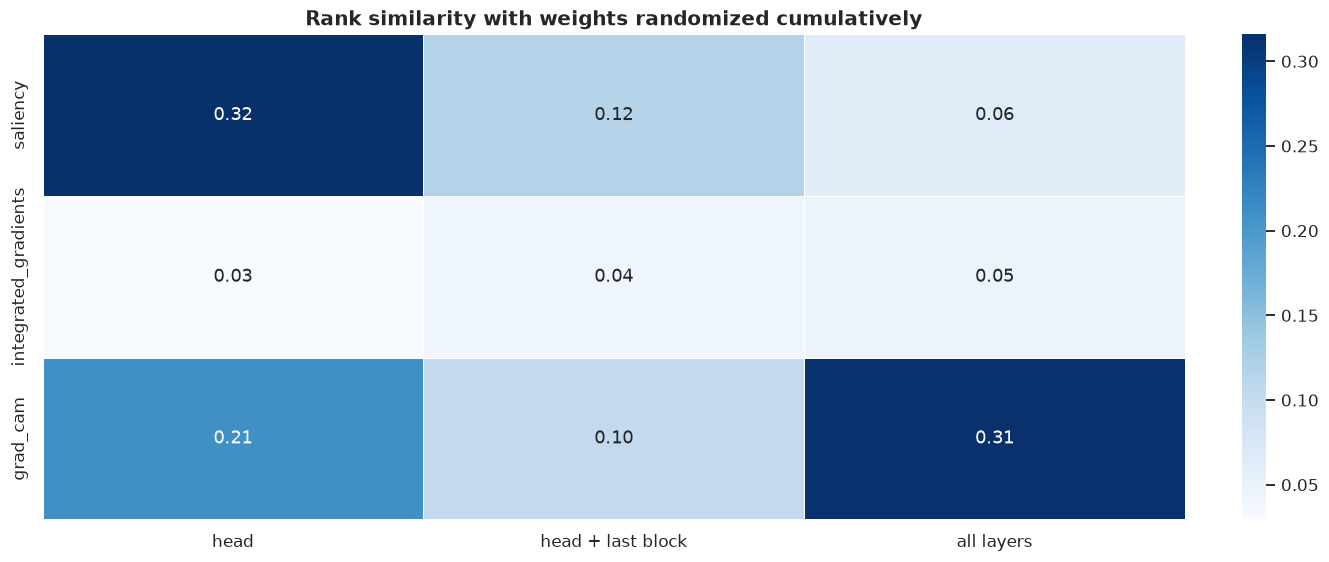

In [13]:
similarity = SanityCheck(model, cohort, normalizer).similarity_table(attribution, selected_rows)
Charts.heatmap(similarity, "Rank similarity with weights randomized cumulatively", value_format=".2f", size=BASE_FIGURE_SIZE)

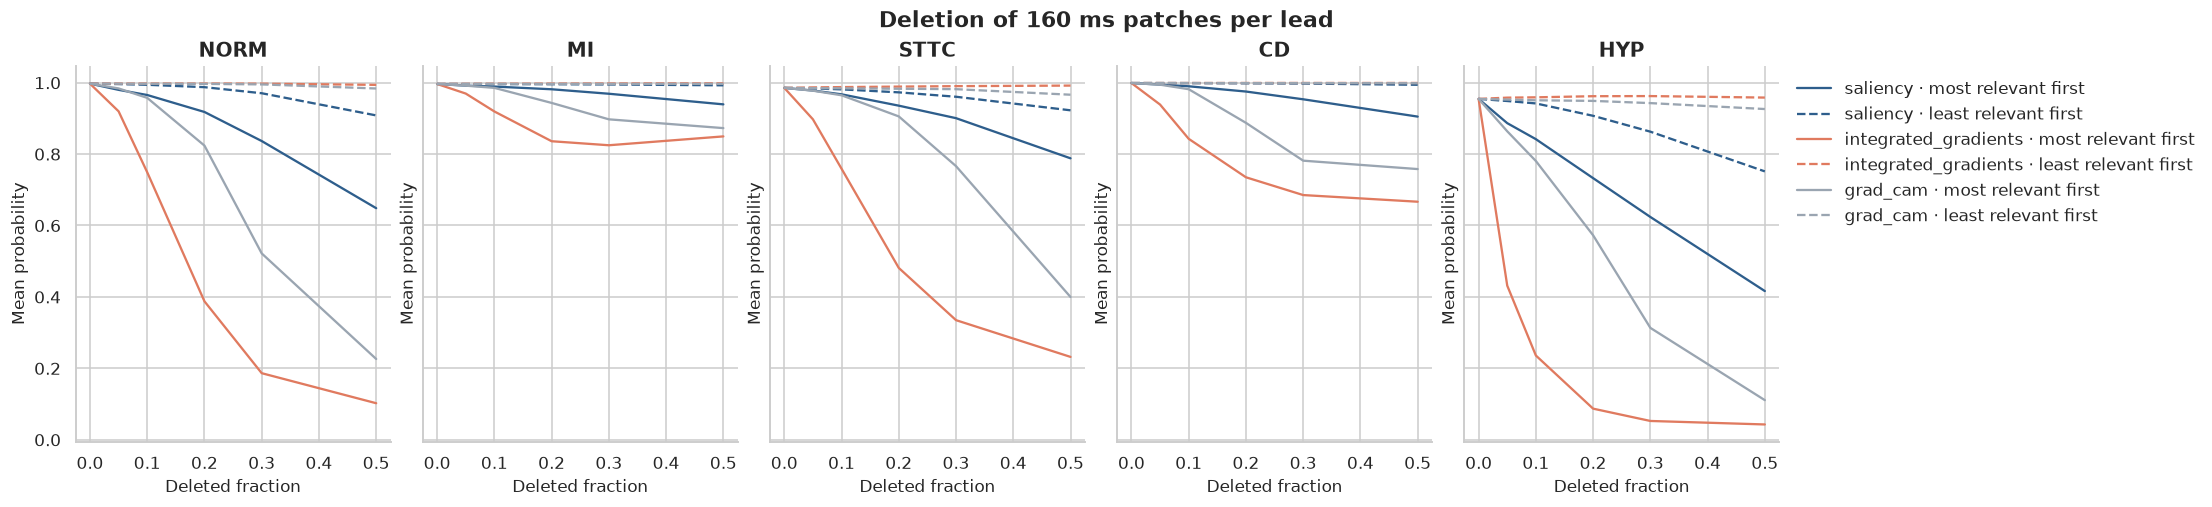

In [14]:
deletion = DeletionTest(model)
deletion_curves = {}
for class_index, (superclass, rows) in enumerate(selected_rows.items()):
    signals, metadata = attribution.inputs(rows)
    relevance = {method: attribution.relevance(method, rows, class_index) for method in METHODS}
    deletion_curves[superclass] = {method: tuple(deletion.curve(signals, metadata, relevance[method], class_index, descending) for descending in (True, False)) for method in METHODS}
Charts.deletion_curves(deletion_curves, "Deletion of 160 ms patches per lead")

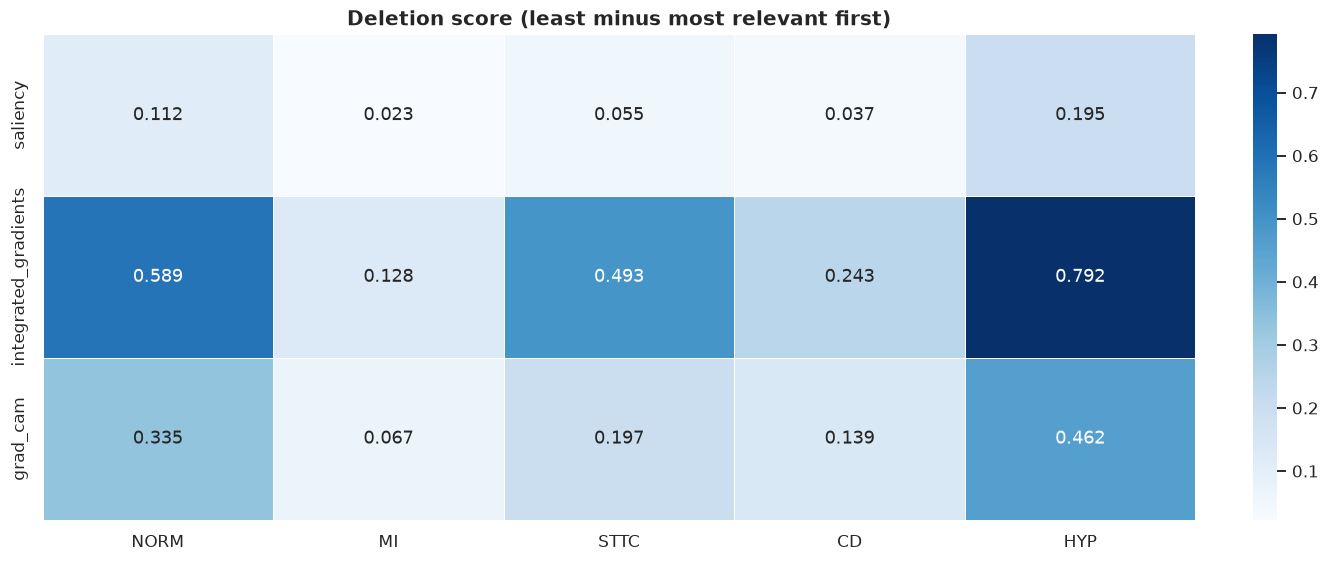

In [15]:
deletion_scores = pd.DataFrame({superclass: {method: deletion.score(*curves) for method, curves in methods.items()} for superclass, methods in deletion_curves.items()})
Charts.heatmap(deletion_scores, "Deletion score (least minus most relevant first)", value_format=".3f", size=BASE_FIGURE_SIZE)

In [16]:
sanity_passed = similarity[RANDOMIZATION_STAGES[-1]].le(SANITY_SIMILARITY_LIMIT)
candidates = [method for method in LEAD_RESOLVED_METHODS if sanity_passed[method]]
primary_method = deletion_scores.loc[candidates].mean(axis=1).idxmax()
print(f"passed sanity check: {sanity_passed[sanity_passed].index.tolist()} | primary method: {primary_method}")

passed sanity check: ['saliency', 'integrated_gradients', 'grad_cam'] | primary method: integrated_gradients


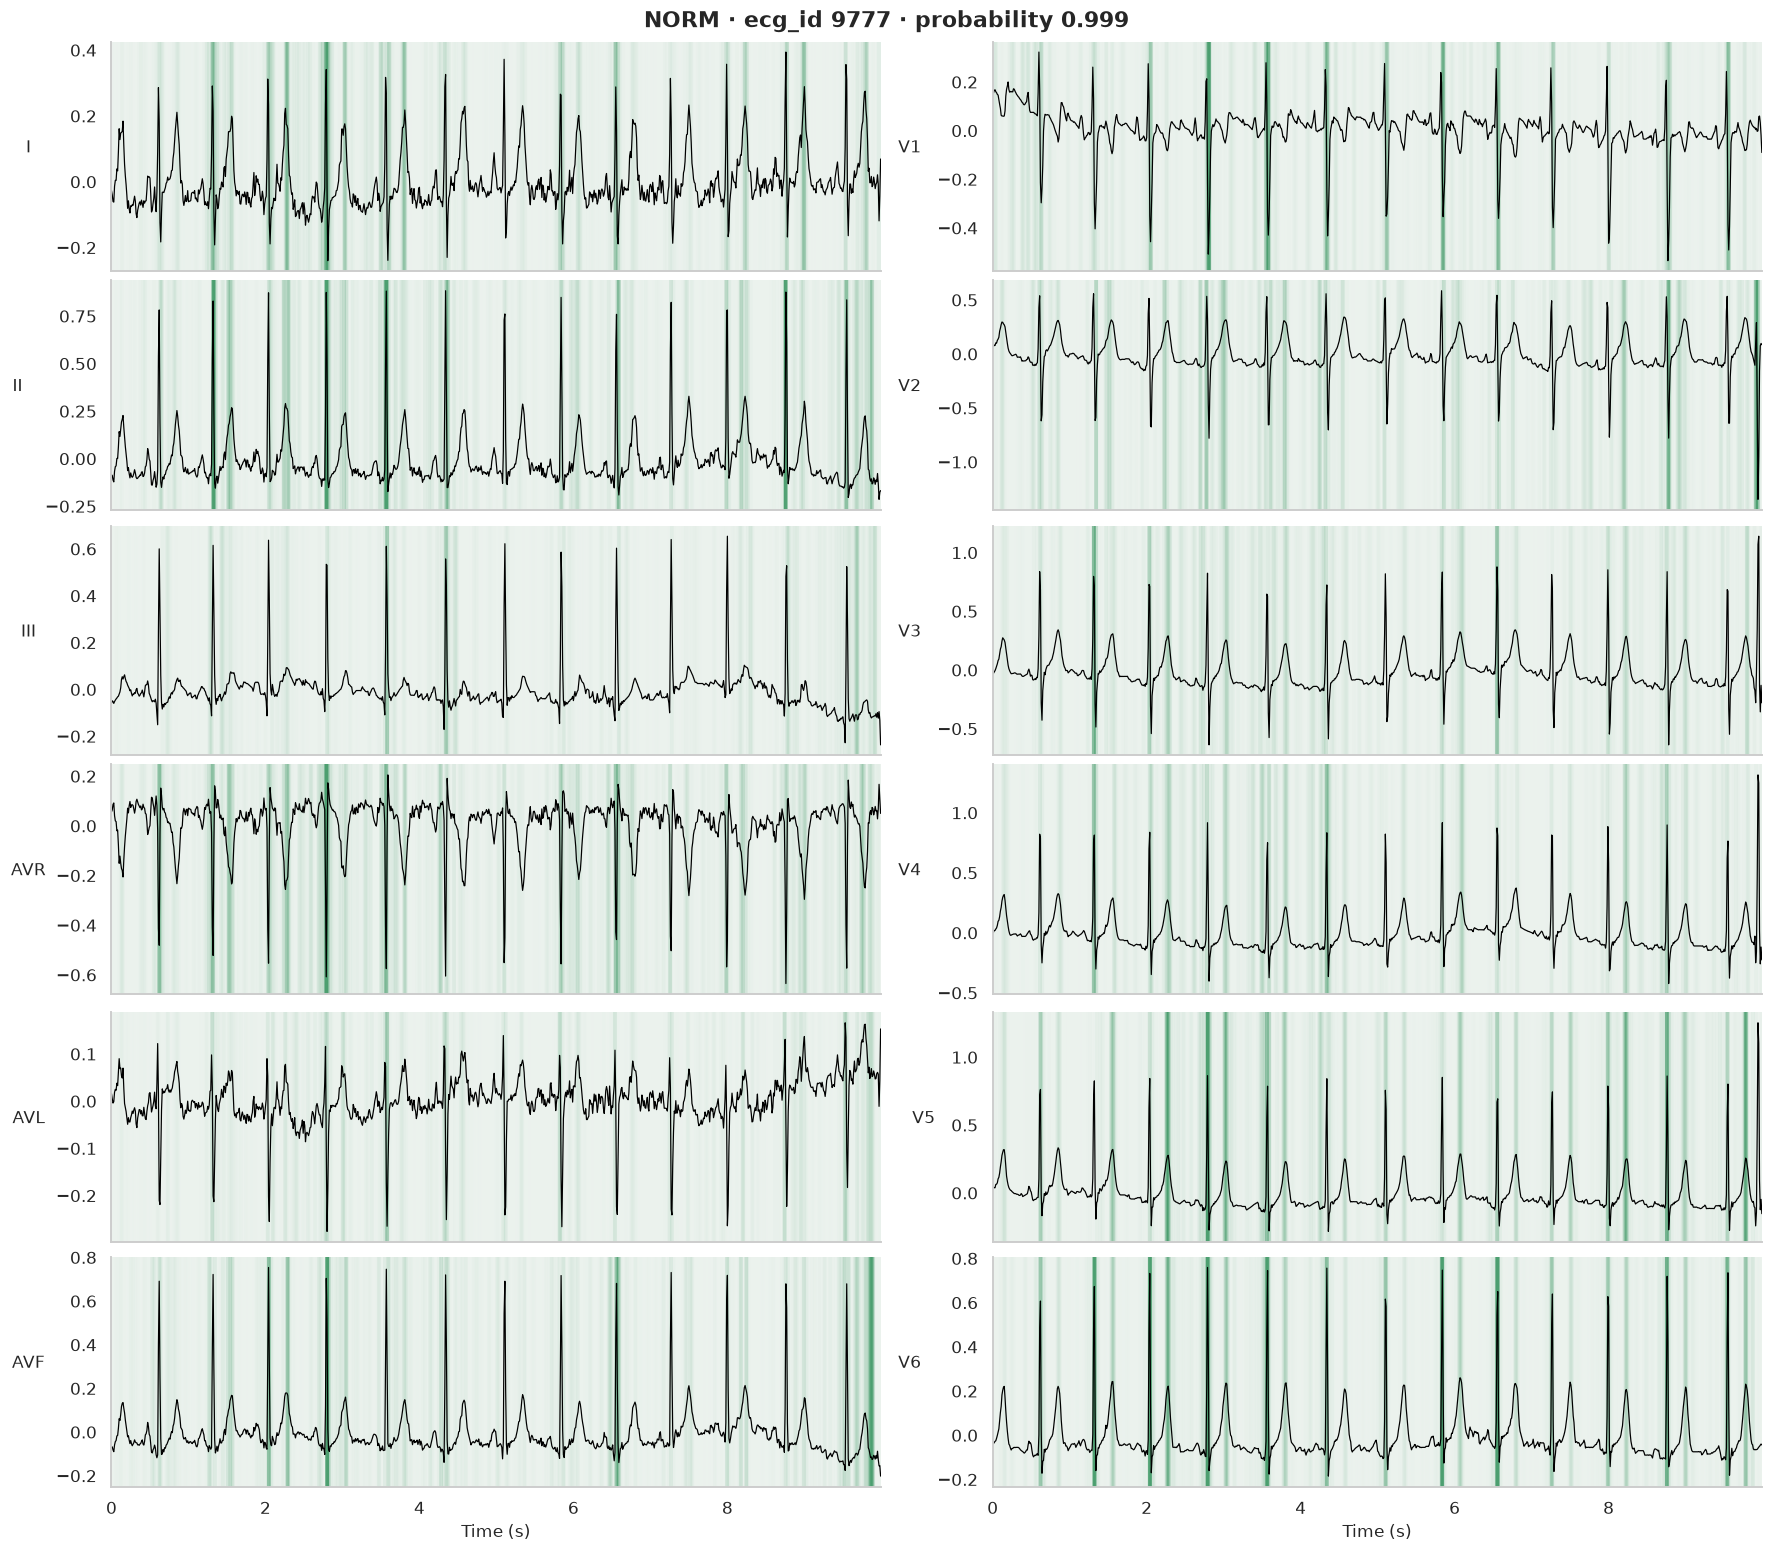

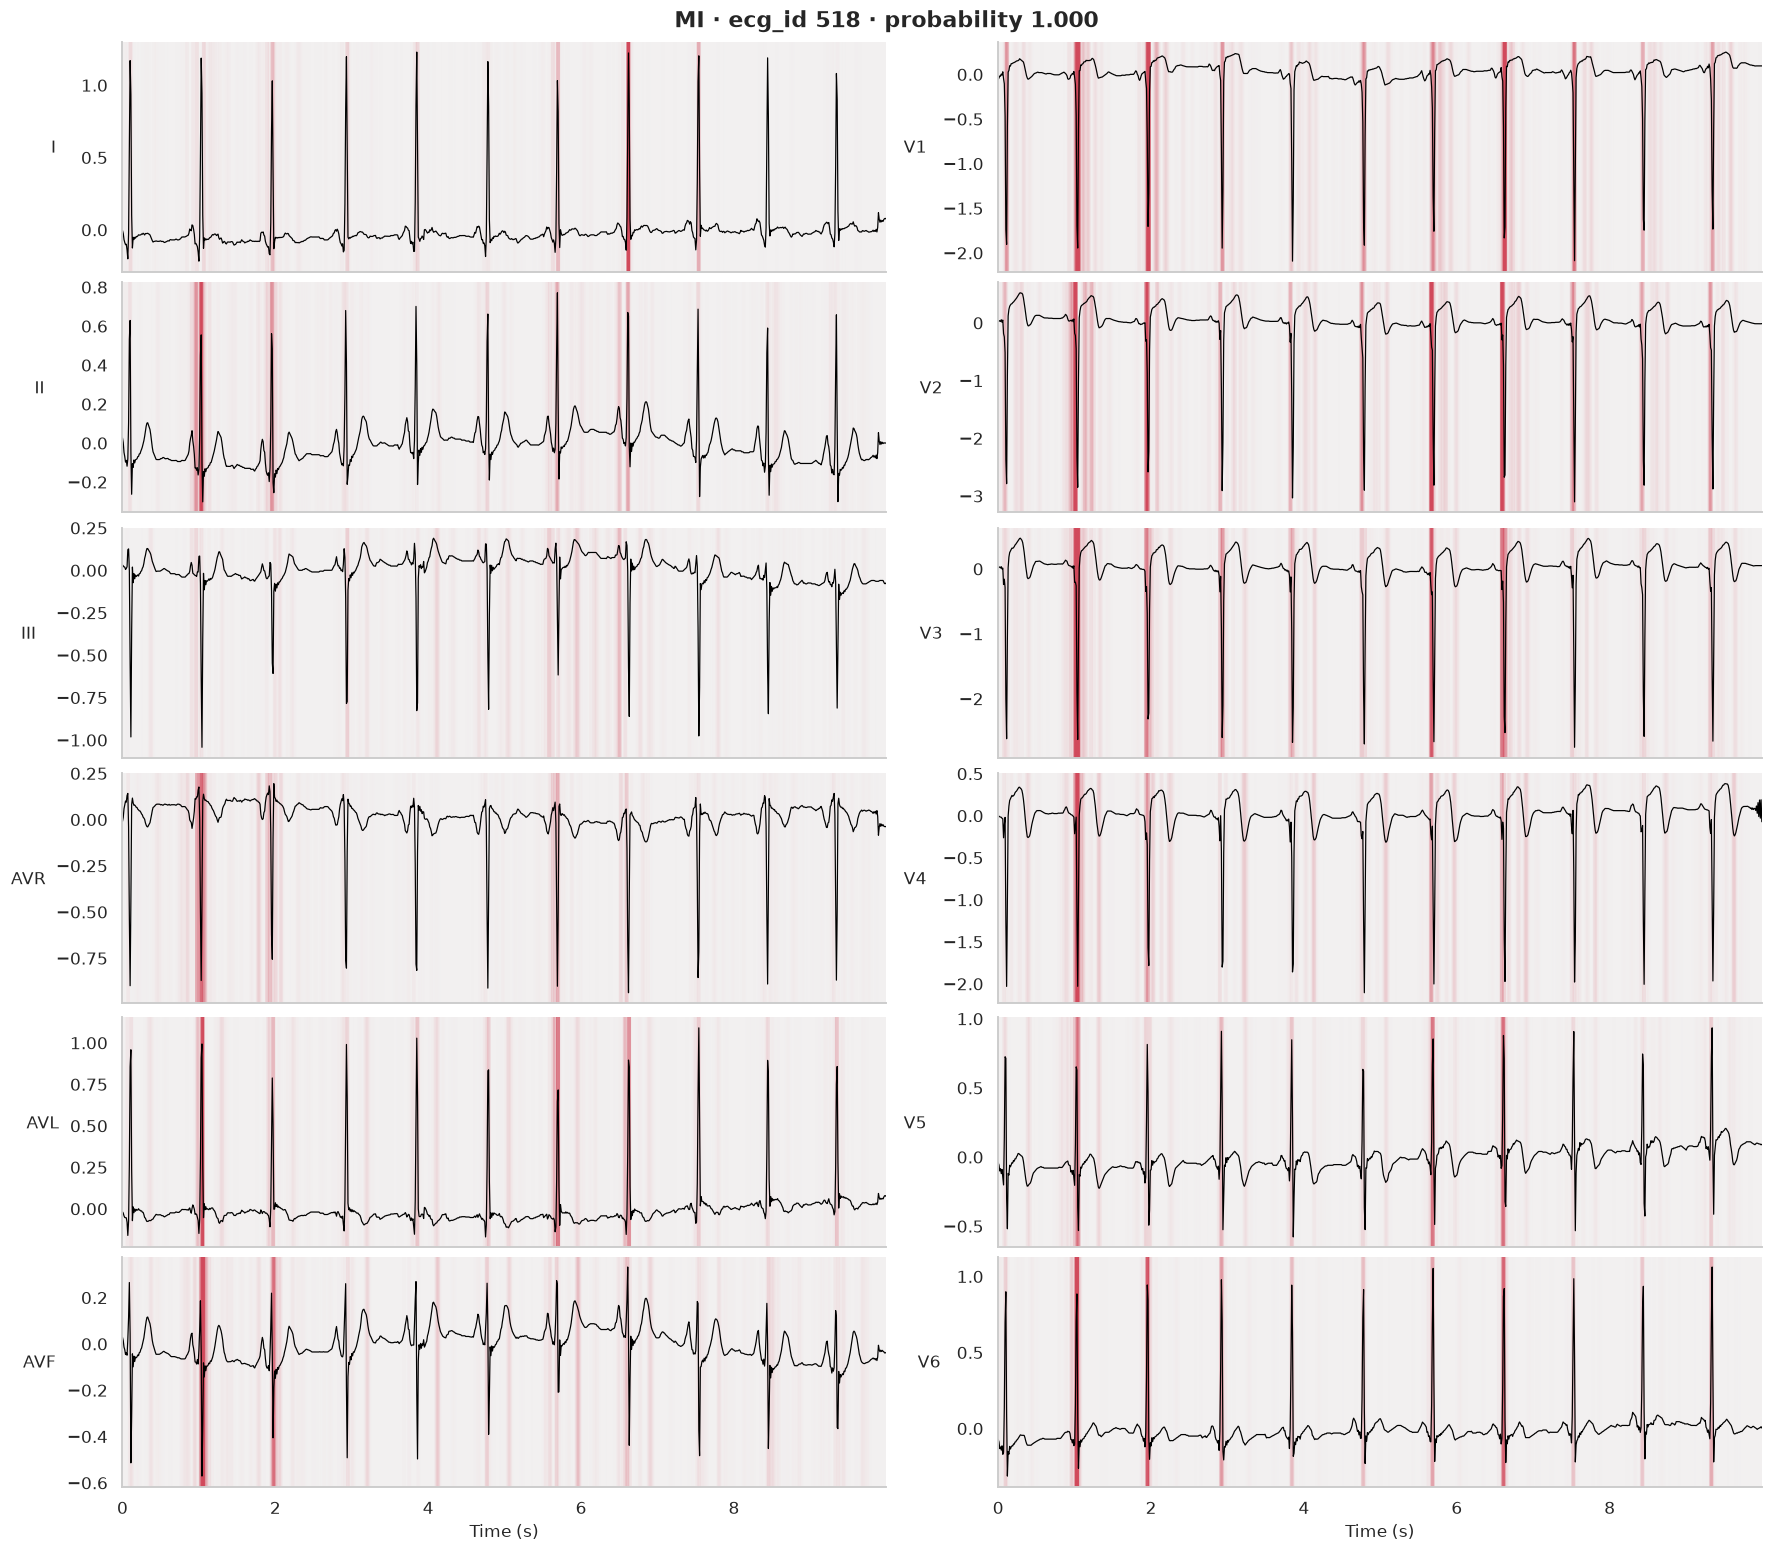

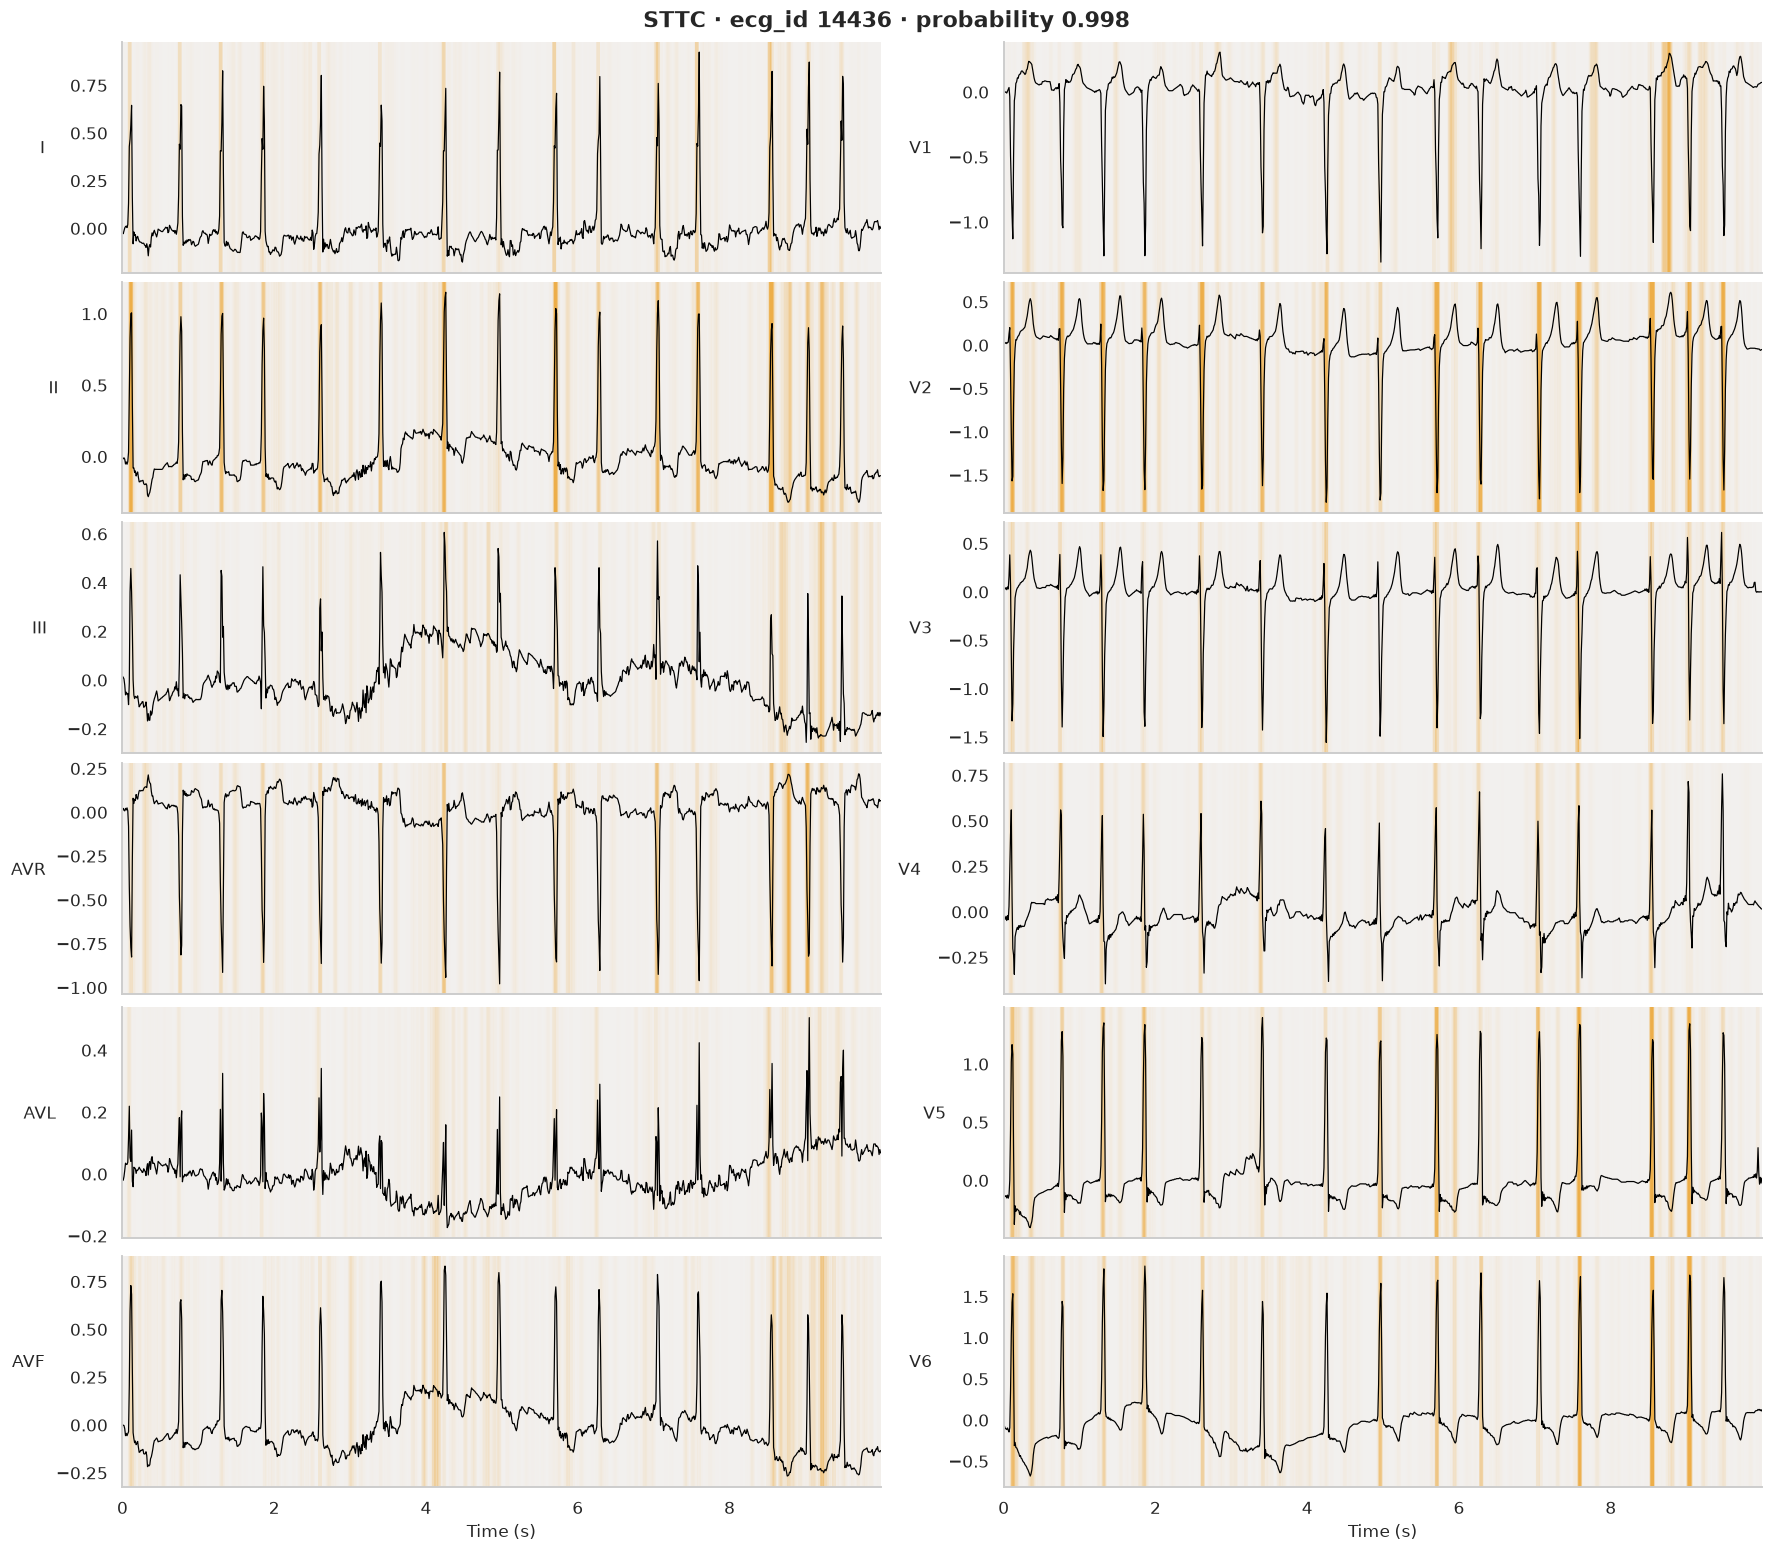

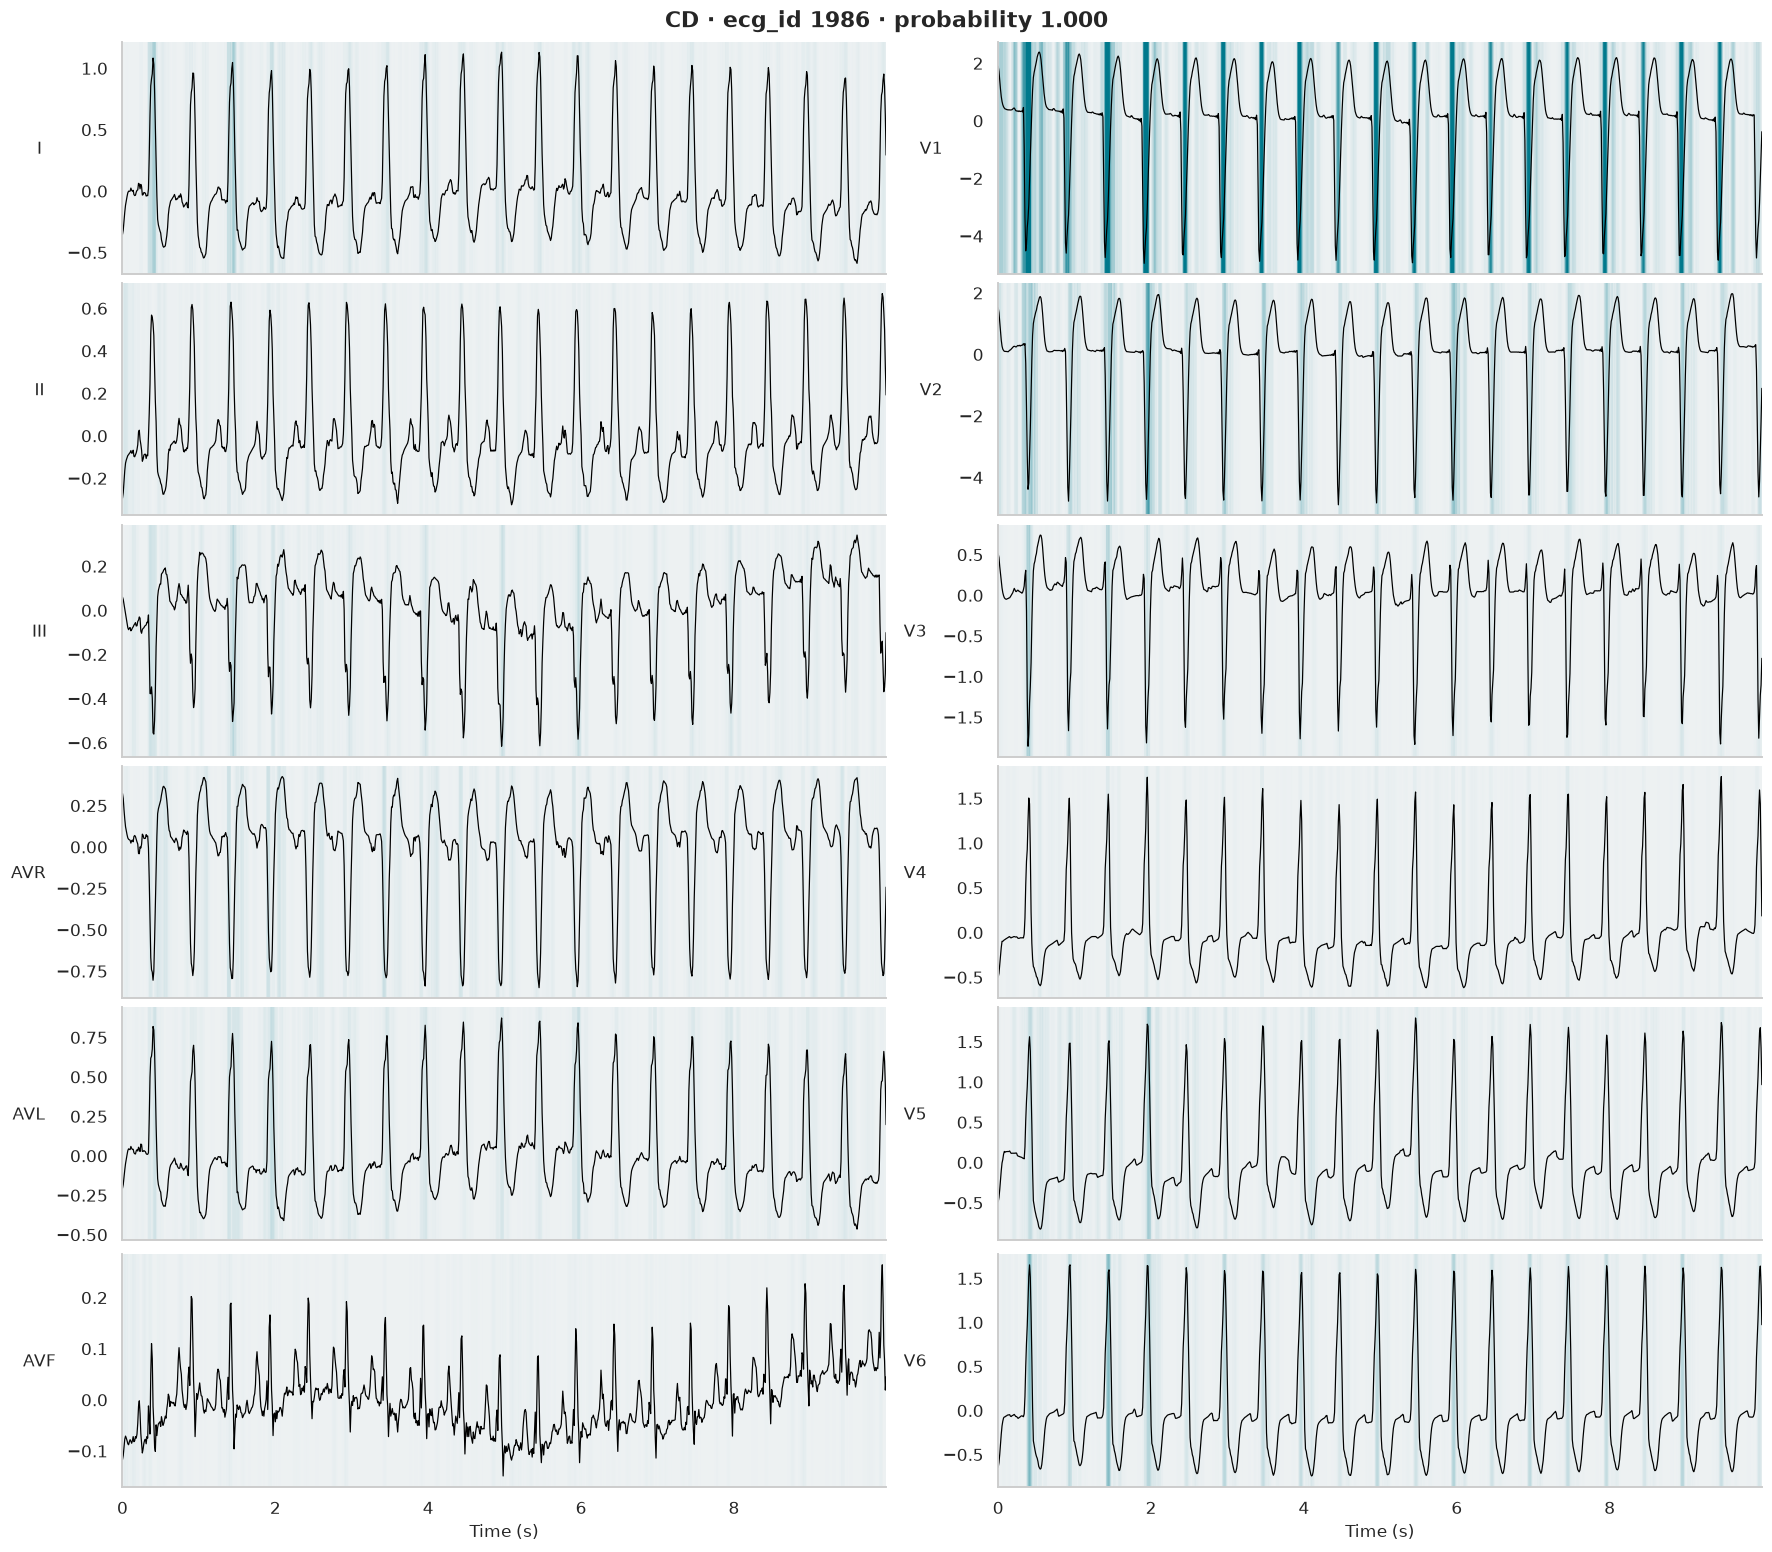

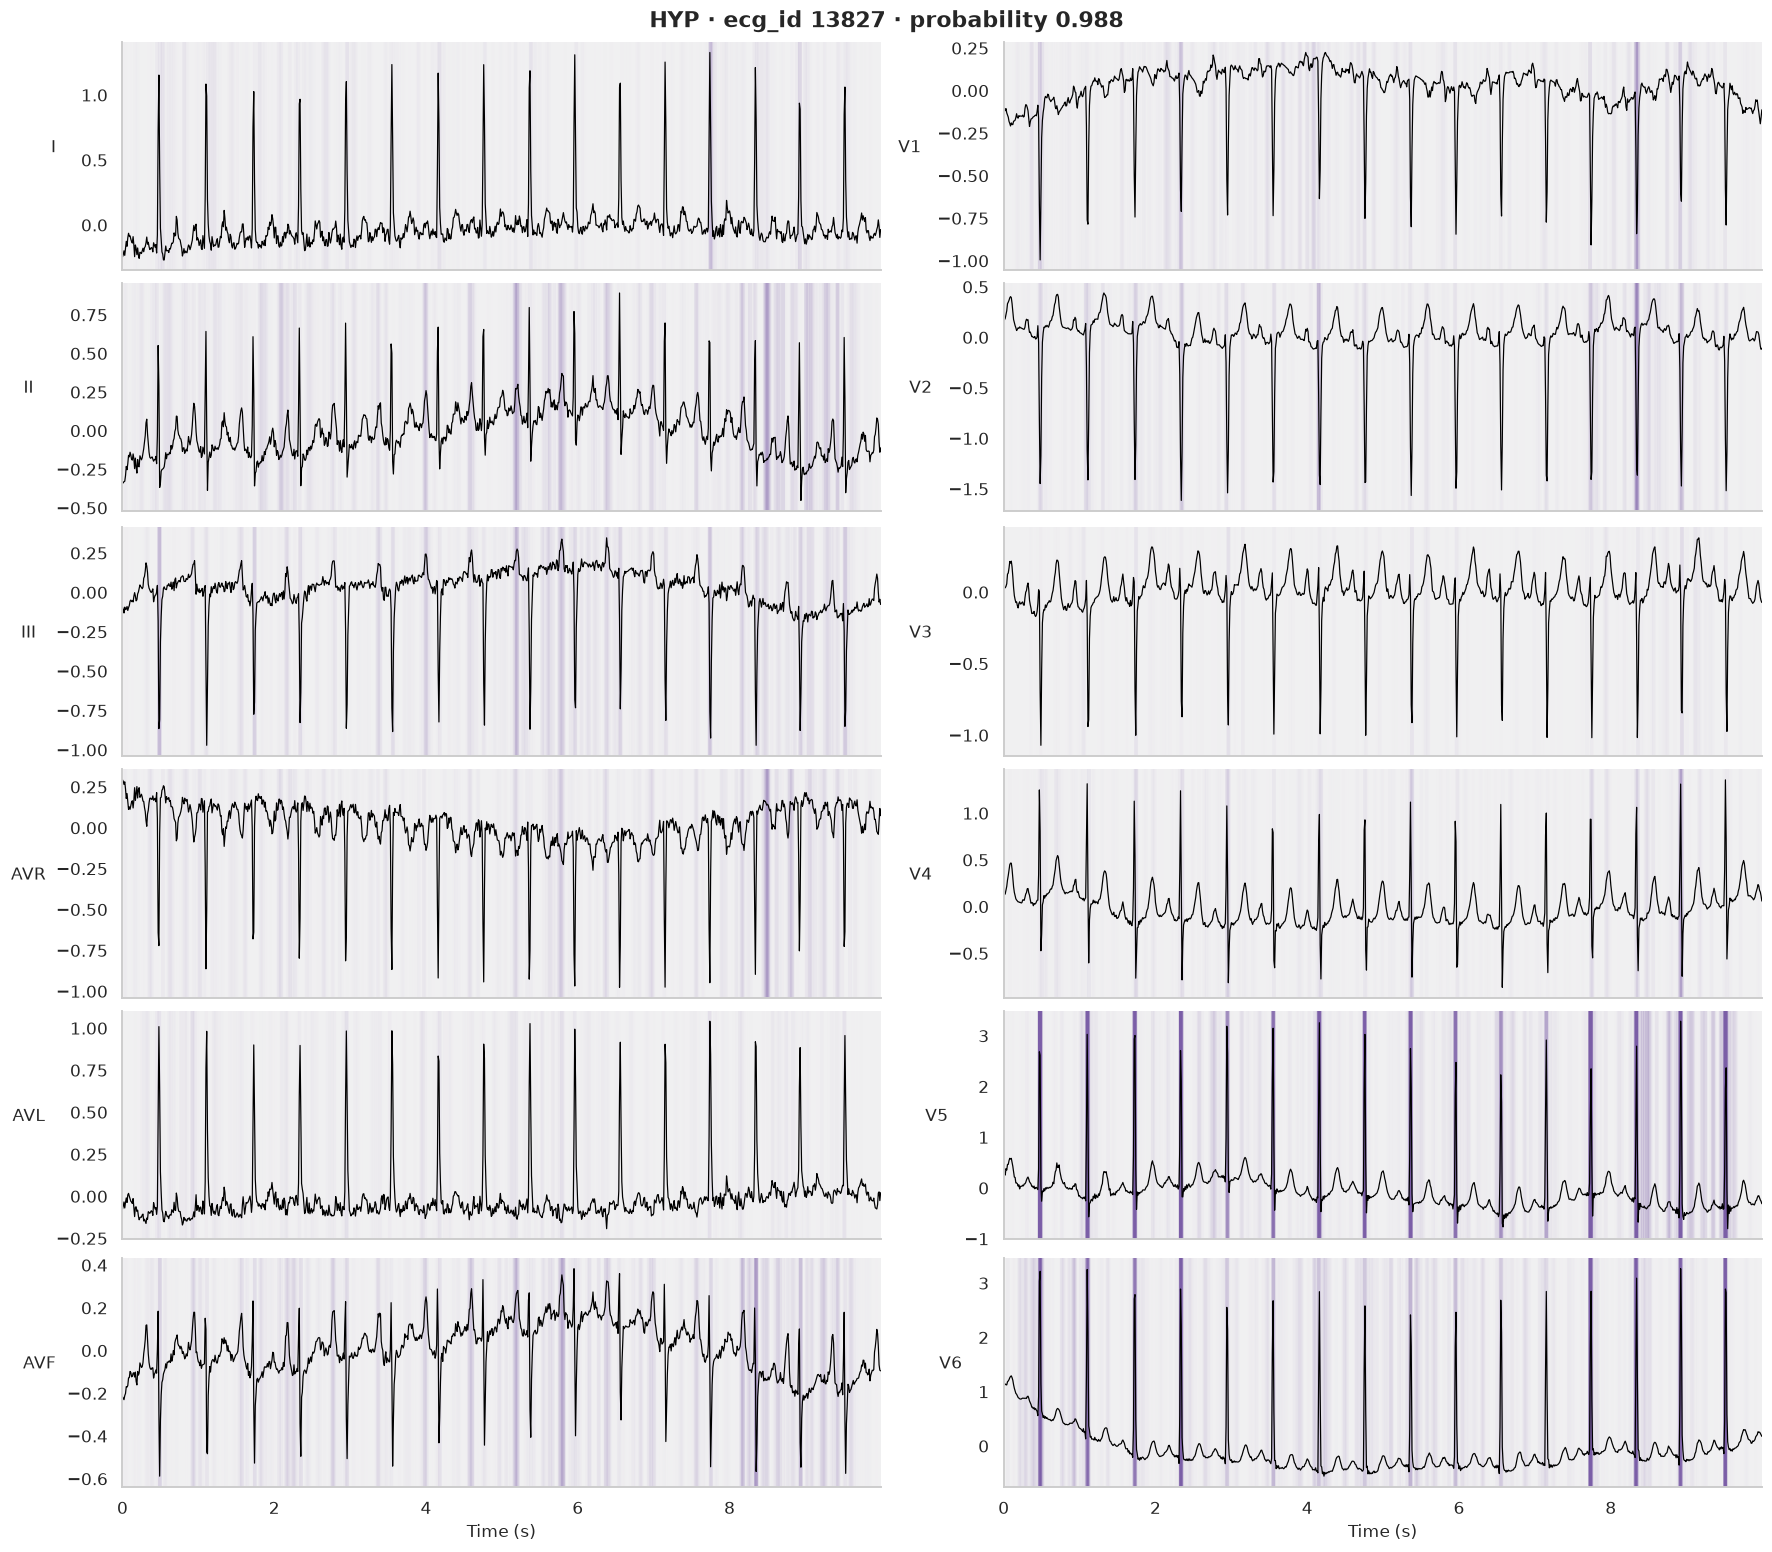

In [17]:
for class_index, superclass in enumerate(SUPERCLASSES):
    ecg_id = selector.single_label_example(superclass)
    rows = cohort.rows([ecg_id])
    title = f"{superclass} · ecg_id {ecg_id} · probability {selector.probabilities.loc[ecg_id, superclass]:.3f}"
    Charts.relevance_leads(cohort.signals[rows][0].cpu().numpy(), attribution.relevance(primary_method, rows, class_index)[0].cpu().numpy(), title, SUPERCLASS_COLORS[superclass])

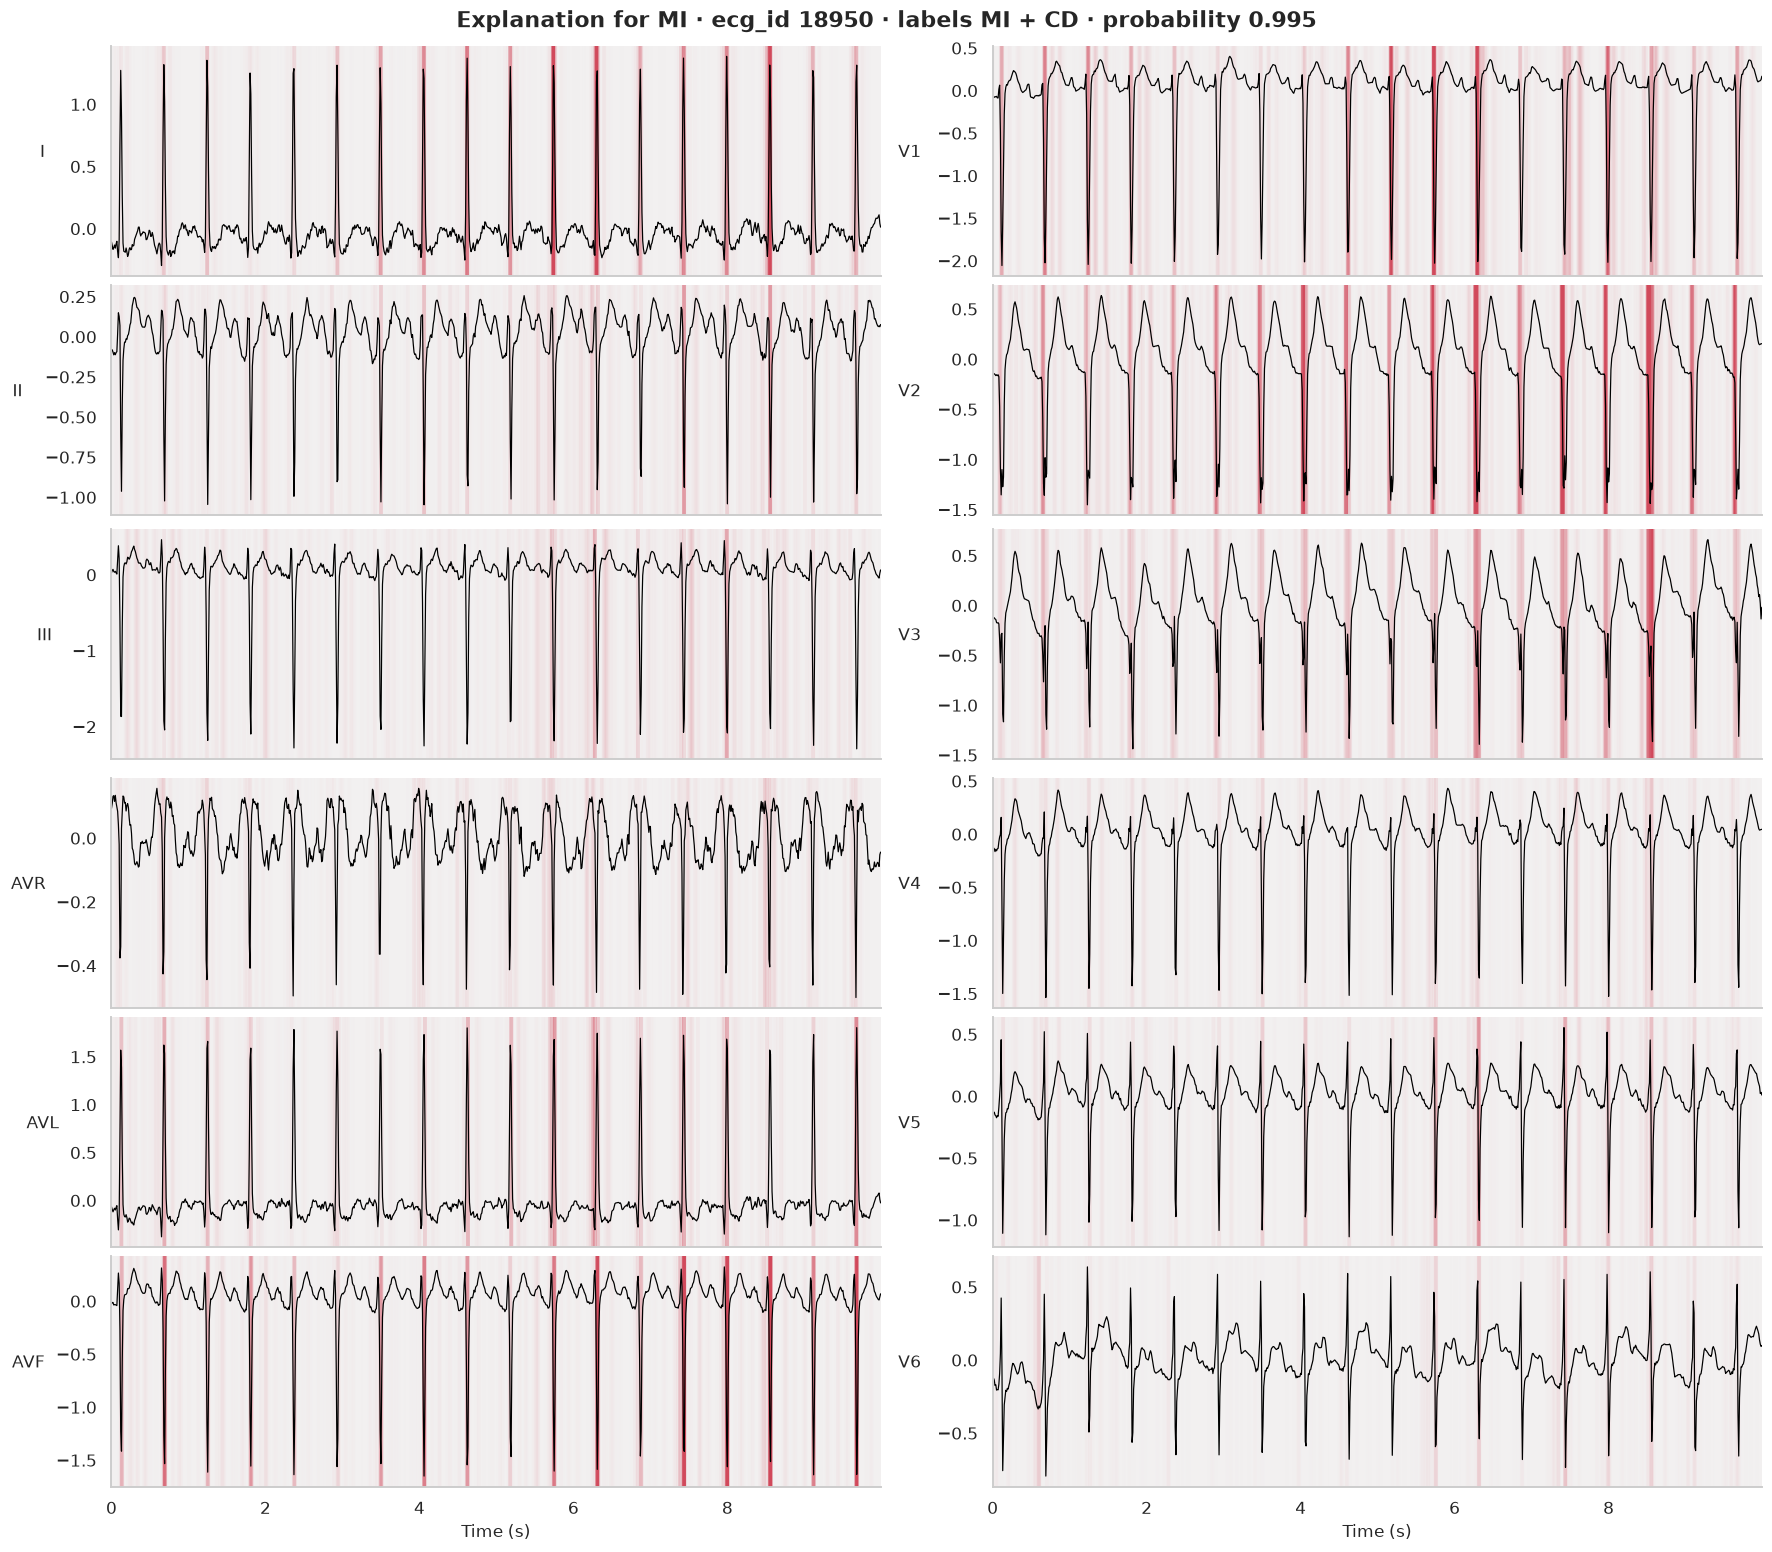

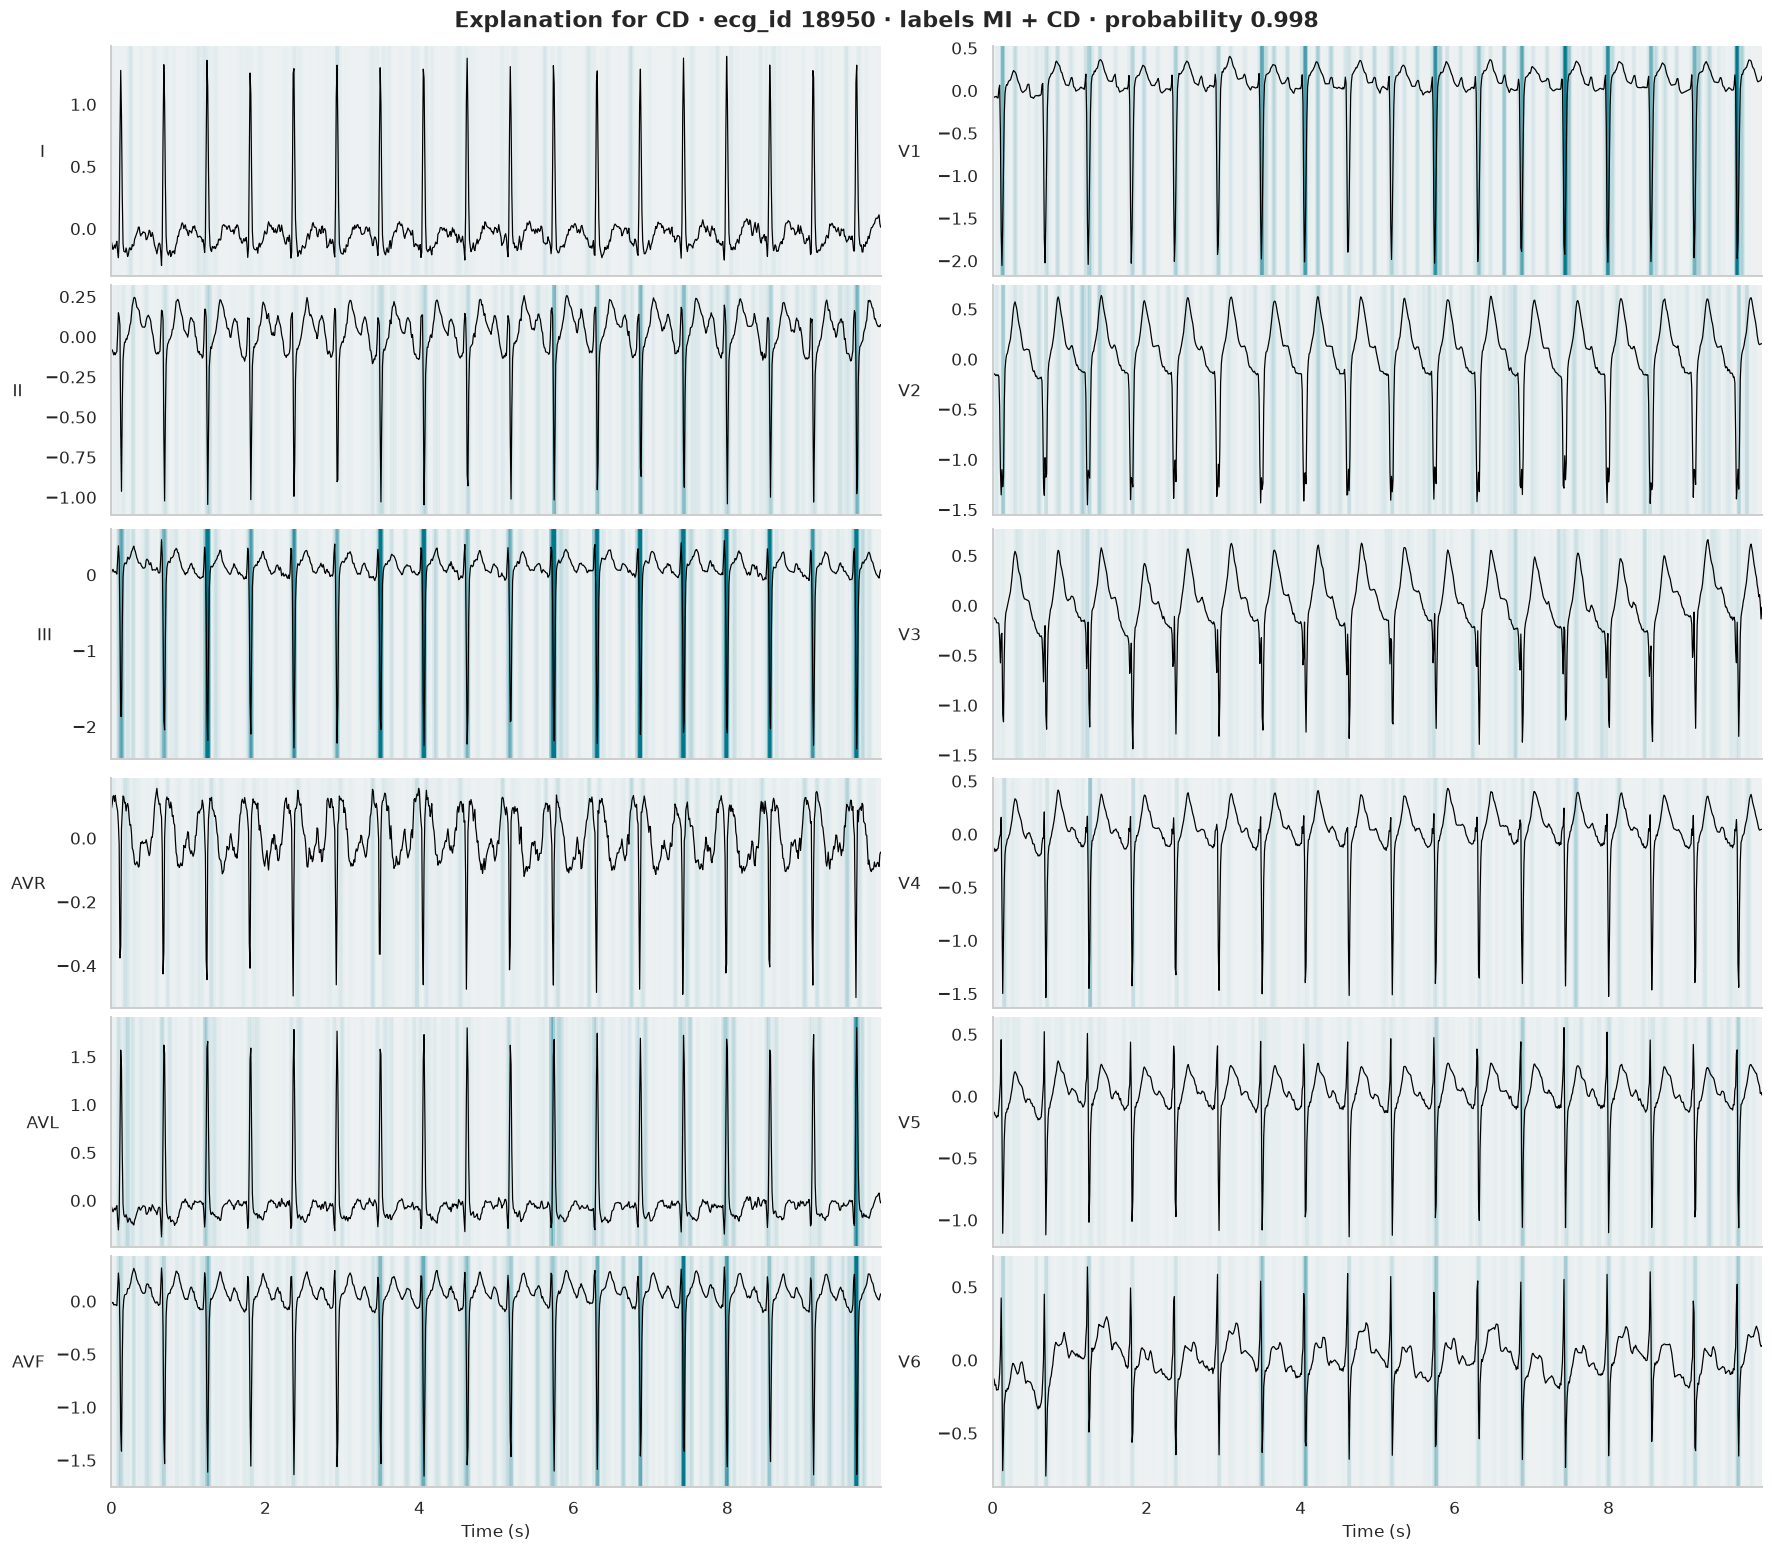

In [18]:
multi_label_id = selector.multi_label_example(MULTI_LABEL_CLASSES)
multi_label_rows = cohort.rows([multi_label_id])
for superclass in MULTI_LABEL_CLASSES:
    title = f"Explanation for {superclass} · ecg_id {multi_label_id} · labels {' + '.join(MULTI_LABEL_CLASSES)} · probability {selector.probabilities.loc[multi_label_id, superclass]:.3f}"
    Charts.relevance_leads(cohort.signals[multi_label_rows][0].cpu().numpy(), attribution.relevance(primary_method, multi_label_rows, SUPERCLASSES.index(superclass))[0].cpu().numpy(), title, SUPERCLASS_COLORS[superclass])

records with an RR estimate: 4250 of 4250 | median RR: 0.84 s


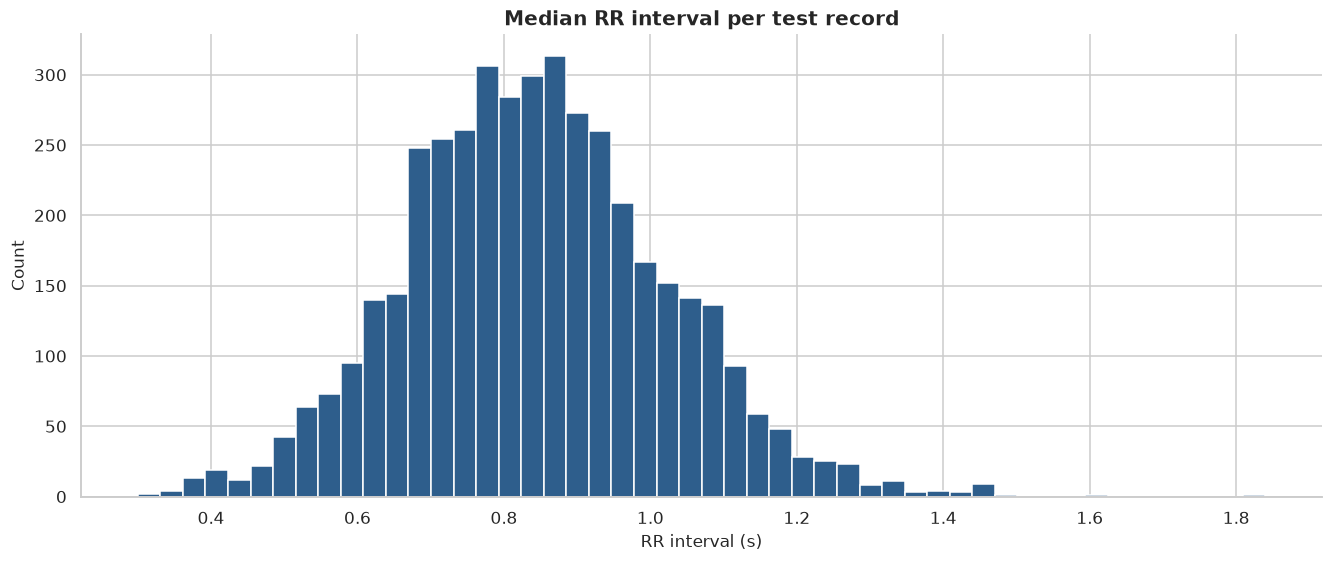

In [19]:
test_signals = cohort.signals[cohort.test_rows()].cpu().numpy()
rr_seconds = BeatLocator.rr_seconds(test_signals)
print(f"records with an RR estimate: {len(rr_seconds)} of {len(test_signals)} | median RR: {np.median(rr_seconds):.2f} s")
Charts.histogram(rr_seconds, "Median RR interval per test record", "RR interval (s)")

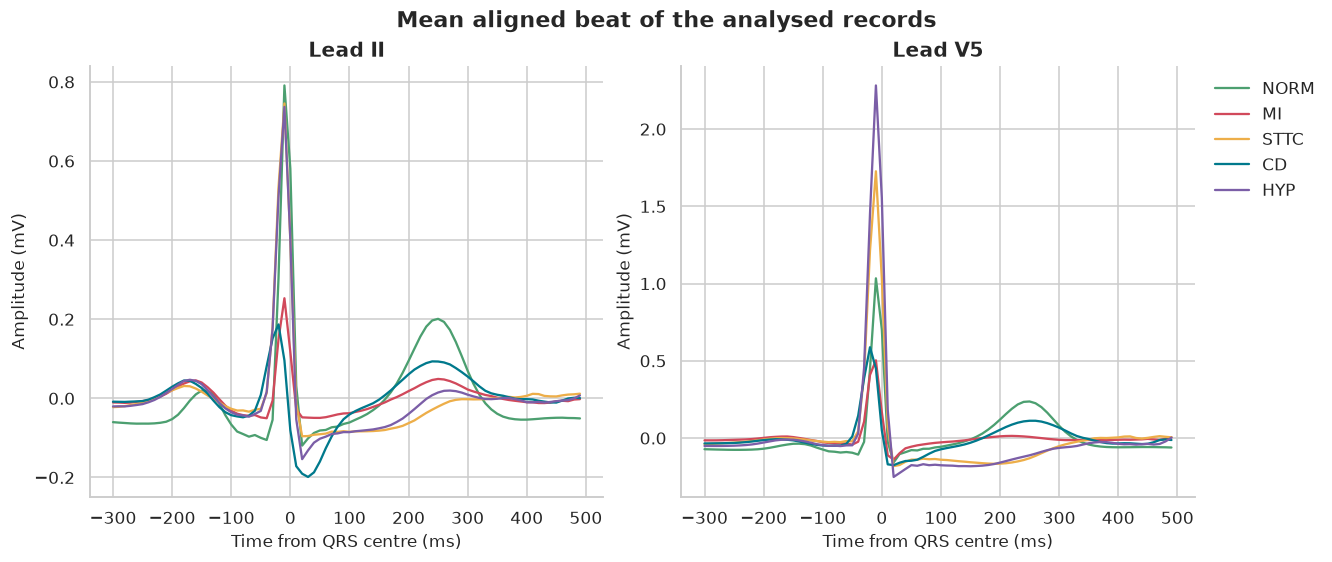

In [20]:
class_signals = {superclass: cohort.signals[rows].cpu().numpy() for superclass, rows in selected_rows.items()}
templates = {superclass: {lead: BeatProfile.template(signals, lead) for lead in TEMPLATE_LEADS} for superclass, signals in class_signals.items()}
Charts.beat_templates(templates, "Mean aligned beat of the analysed records")

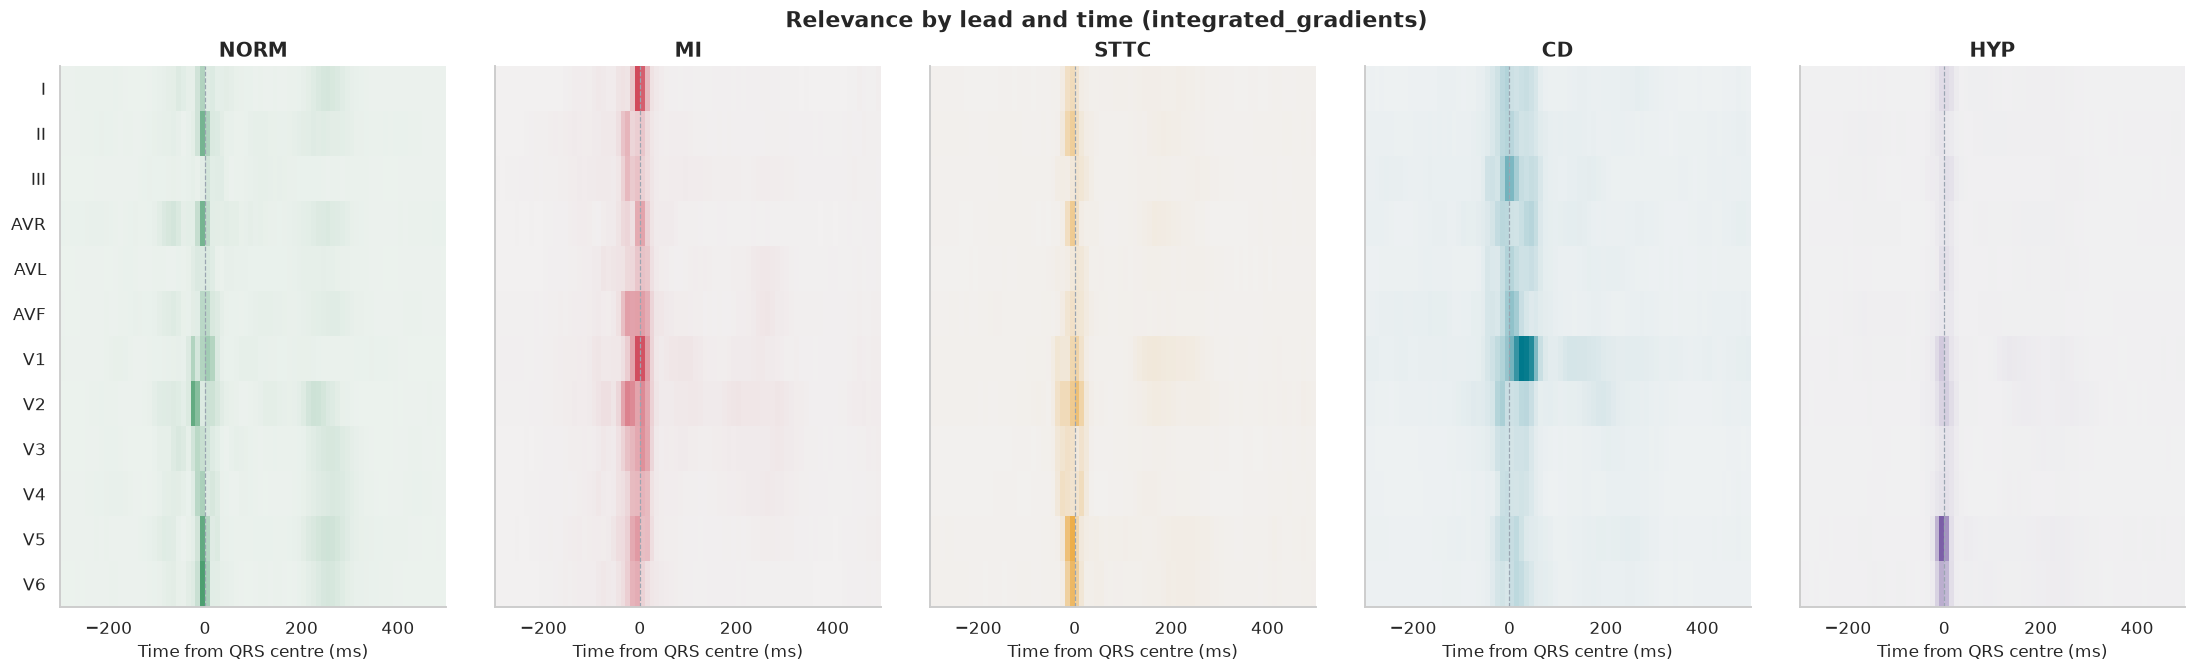

In [21]:
class_relevance = {superclass: attribution.relevance(primary_method, rows, class_index).cpu().numpy() for class_index, (superclass, rows) in enumerate(selected_rows.items())}
beat_matrices = {superclass: BeatProfile.relevance_matrix(class_relevance[superclass], class_signals[superclass]) for superclass in SUPERCLASSES}
Charts.beat_heatmaps(beat_matrices, f"Relevance by lead and time ({primary_method})")

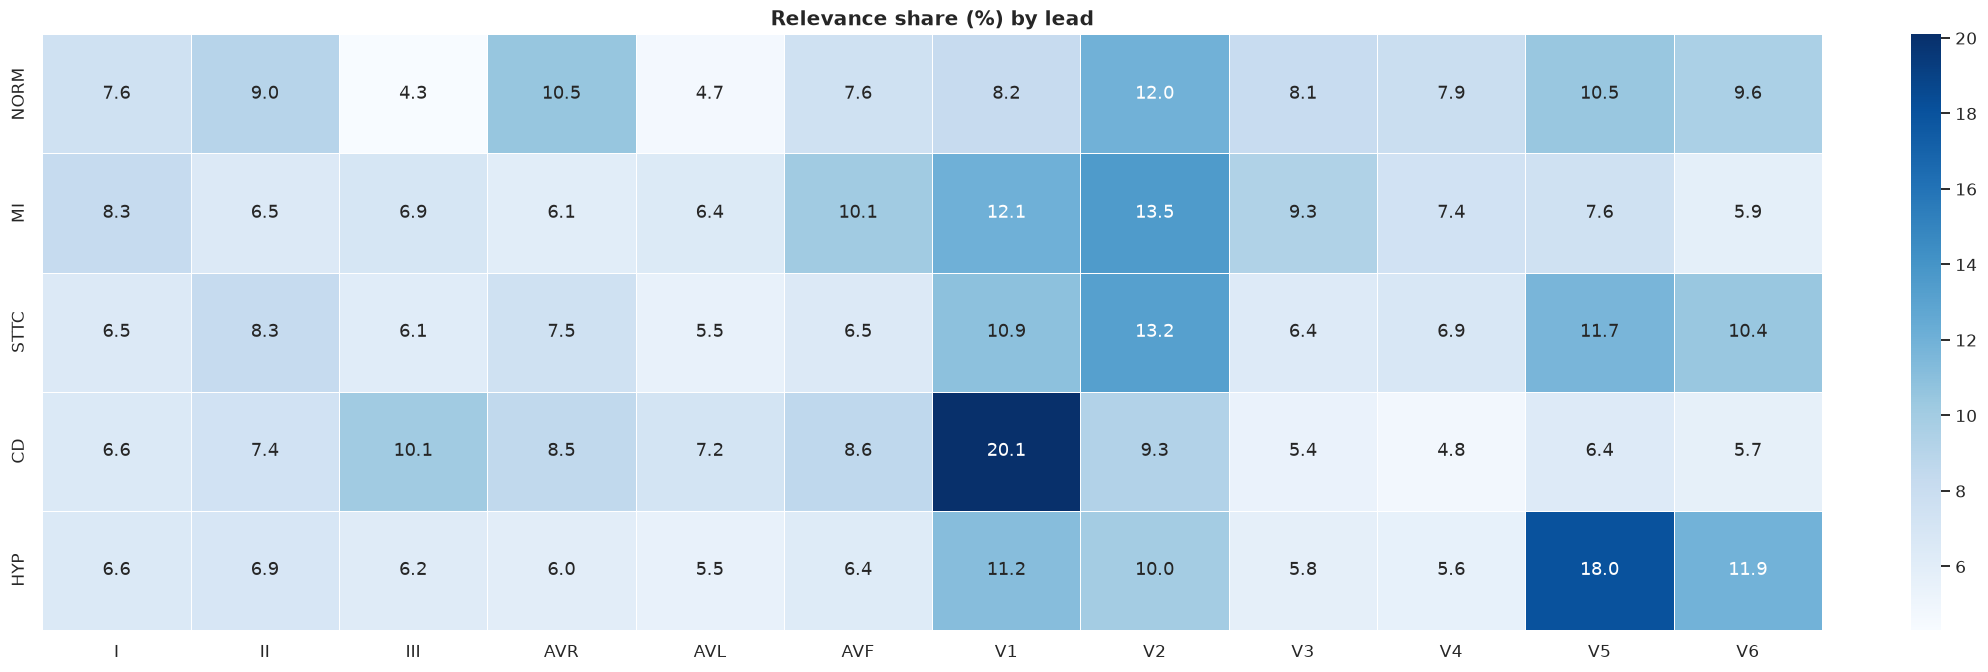

In [22]:
Charts.heatmap(BeatProfile.lead_shares(beat_matrices), "Relevance share (%) by lead", value_format=".1f", size=WIDE_FIGURE_SIZE)

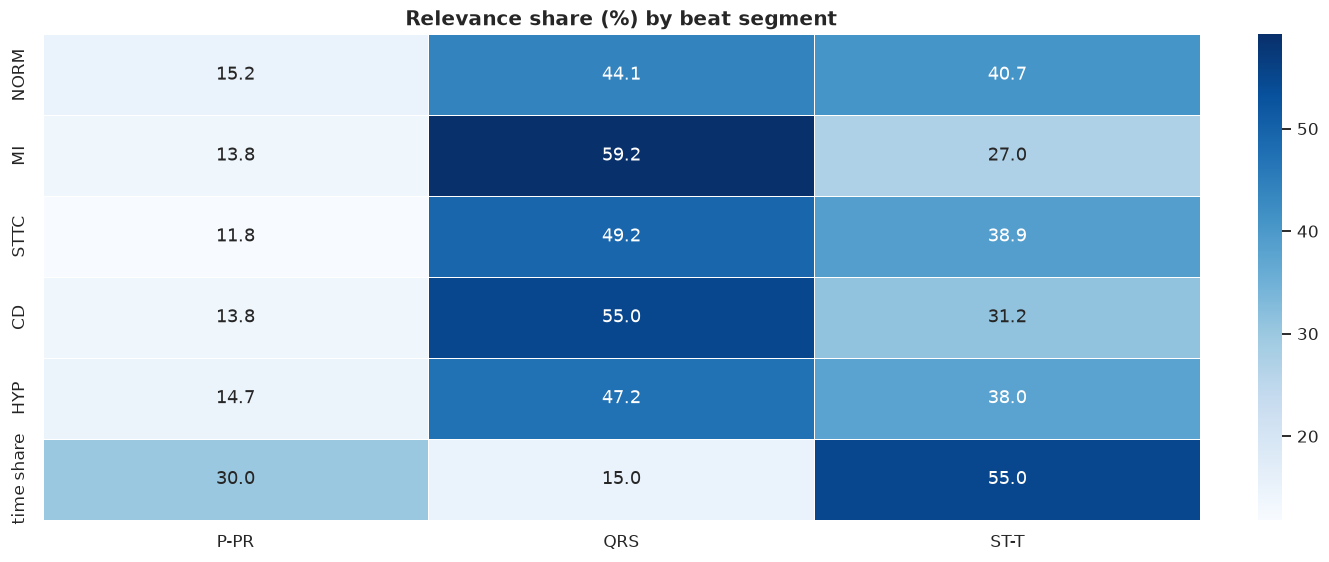

In [23]:
segment_shares = pd.DataFrame({superclass: BeatProfile.segment_shares(matrix) for superclass, matrix in beat_matrices.items()}).T
Charts.heatmap(pd.concat([segment_shares, BeatProfile.time_shares().to_frame("time share").T]), "Relevance share (%) by beat segment", value_format=".1f", size=BASE_FIGURE_SIZE)

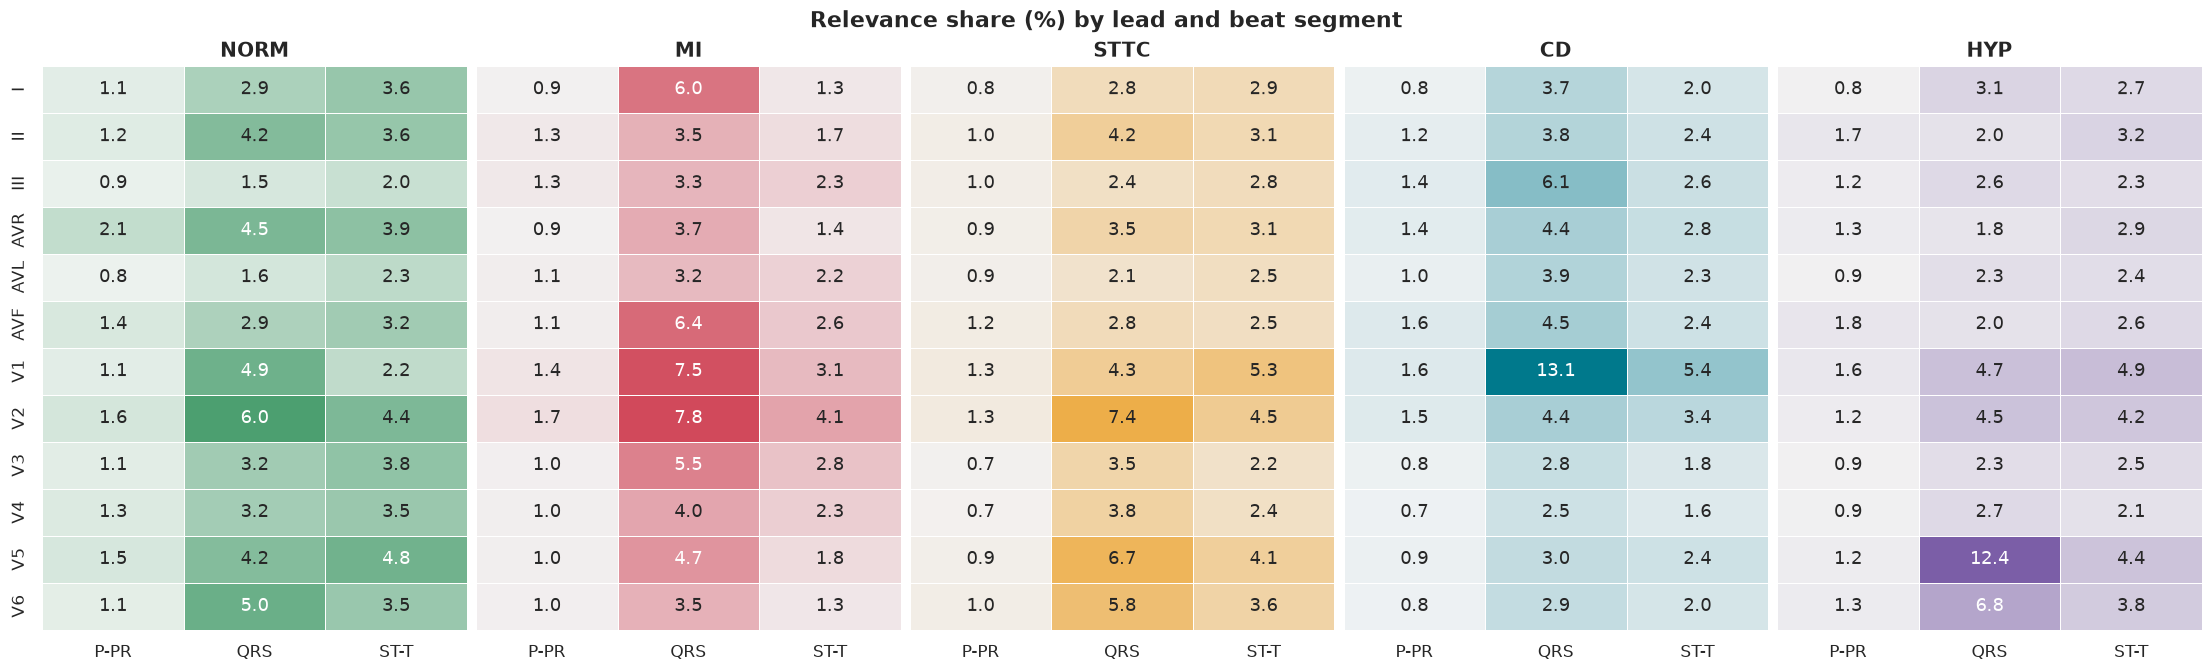

In [24]:
Charts.segment_heatmaps({superclass: BeatProfile.lead_segment_shares(matrix) for superclass, matrix in beat_matrices.items()}, "Relevance share (%) by lead and beat segment")

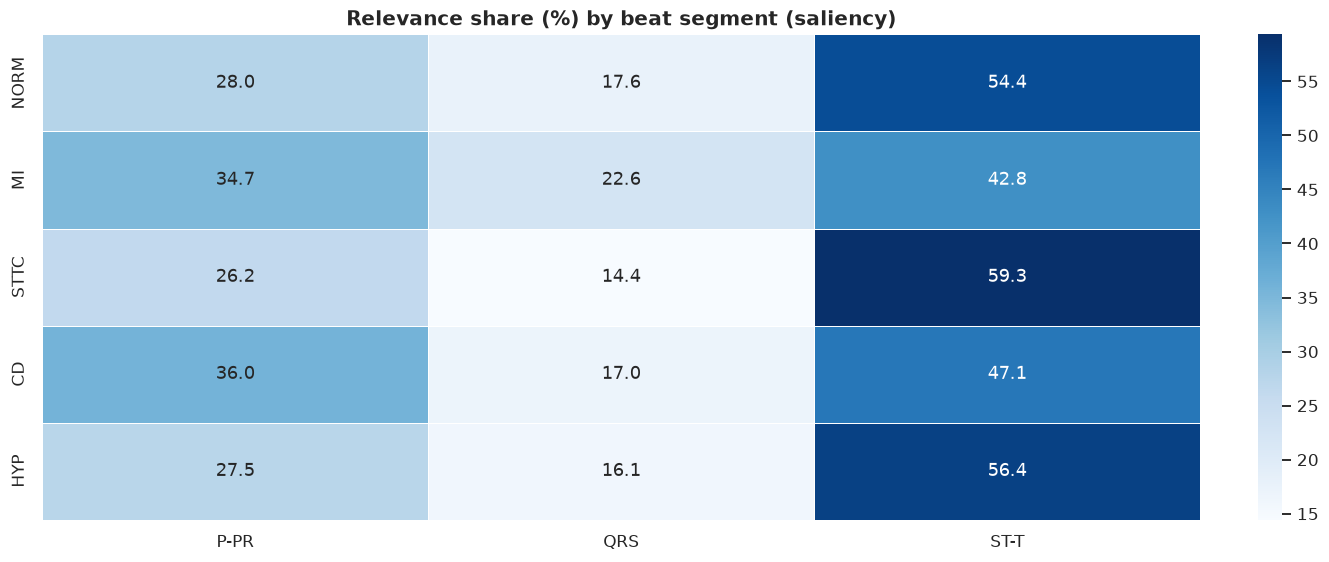

In [25]:
secondary_method = next(method for method in LEAD_RESOLVED_METHODS if method != primary_method)
secondary_matrices = {superclass: BeatProfile.relevance_matrix(attribution.relevance(secondary_method, rows, class_index).cpu().numpy(), class_signals[superclass]) for class_index, (superclass, rows) in enumerate(selected_rows.items())}
Charts.heatmap(pd.DataFrame({superclass: BeatProfile.segment_shares(matrix) for superclass, matrix in secondary_matrices.items()}).T, f"Relevance share (%) by beat segment ({secondary_method})", value_format=".1f", size=BASE_FIGURE_SIZE)

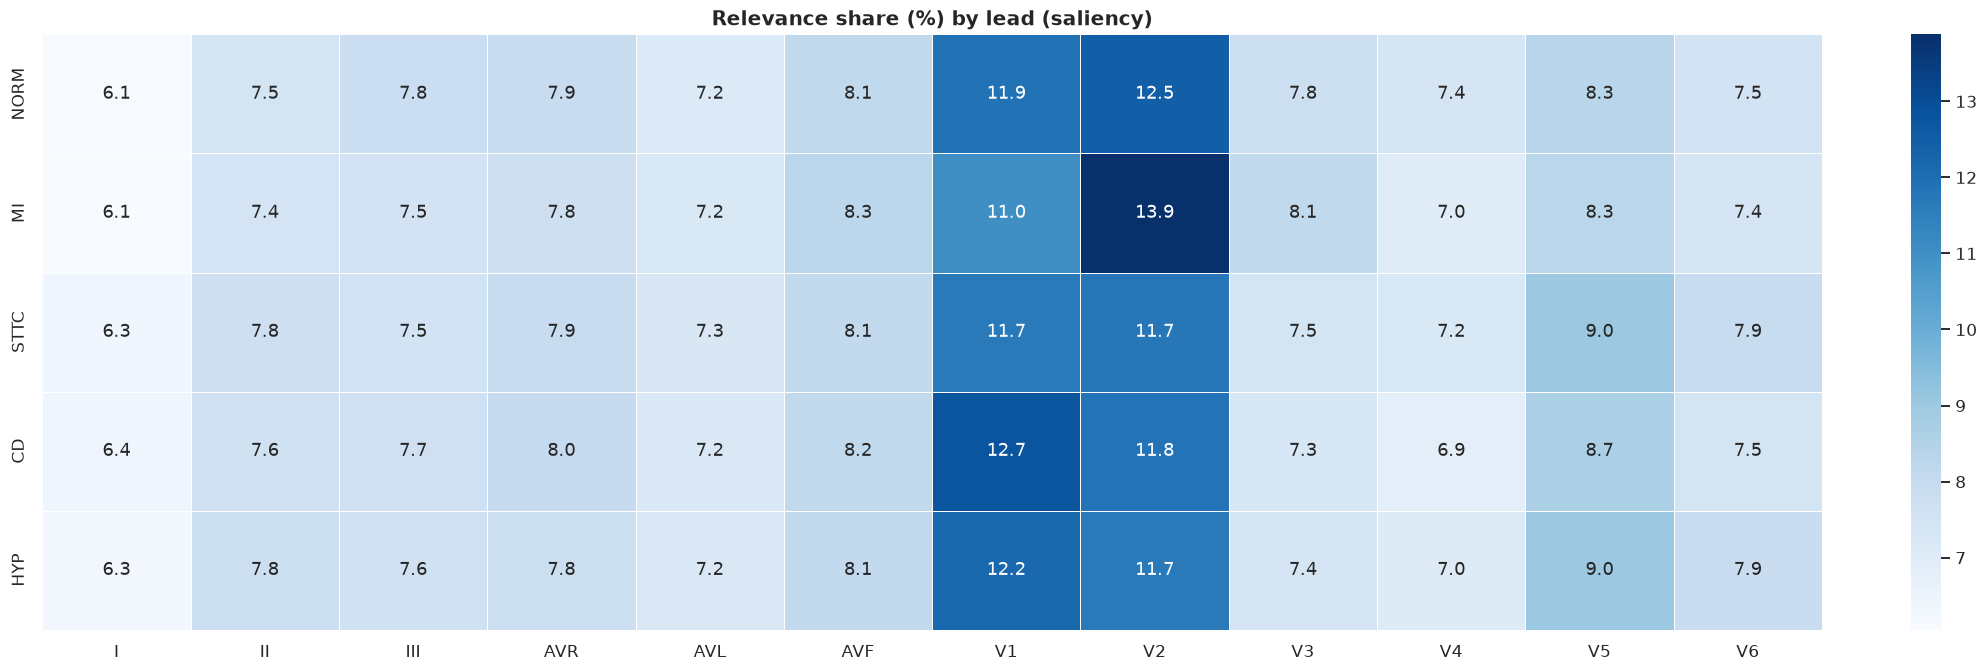

In [26]:
Charts.heatmap(BeatProfile.lead_shares(secondary_matrices), f"Relevance share (%) by lead ({secondary_method})", value_format=".1f", size=WIDE_FIGURE_SIZE)

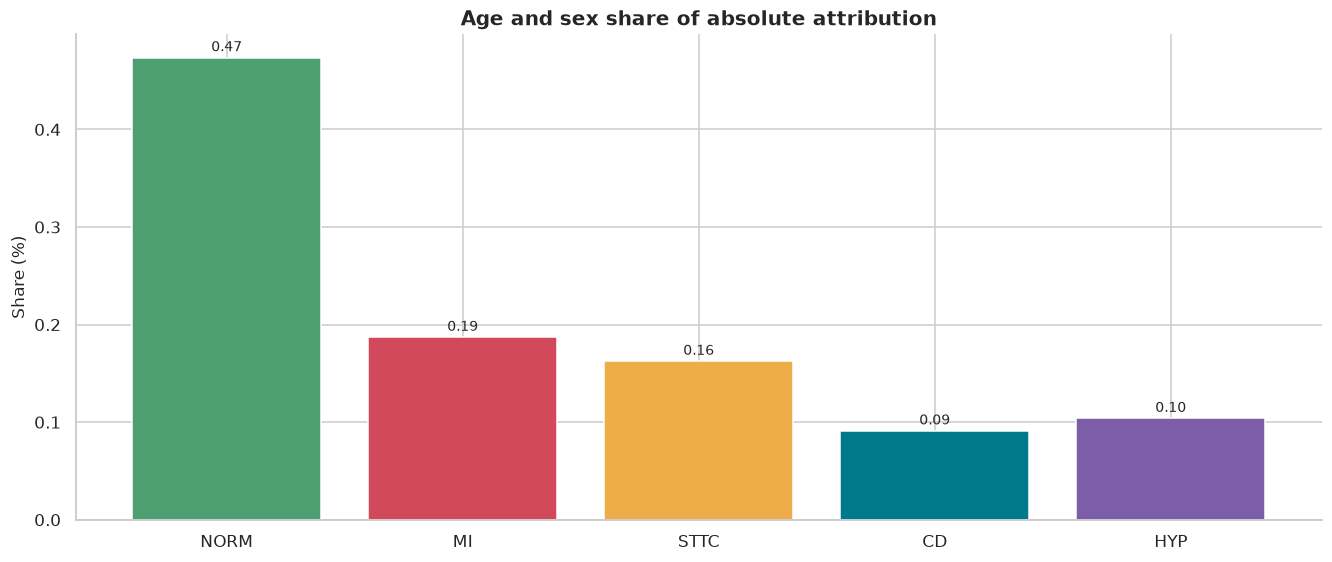

In [27]:
metadata_contribution = MetadataContribution.table(attribution, selected_rows)
Charts.bar(metadata_contribution["metadata_share"], "Age and sex share of absolute attribution", ylabel="Share (%)", color=PlotTheme.class_colors(SUPERCLASSES), value_format="%.2f")

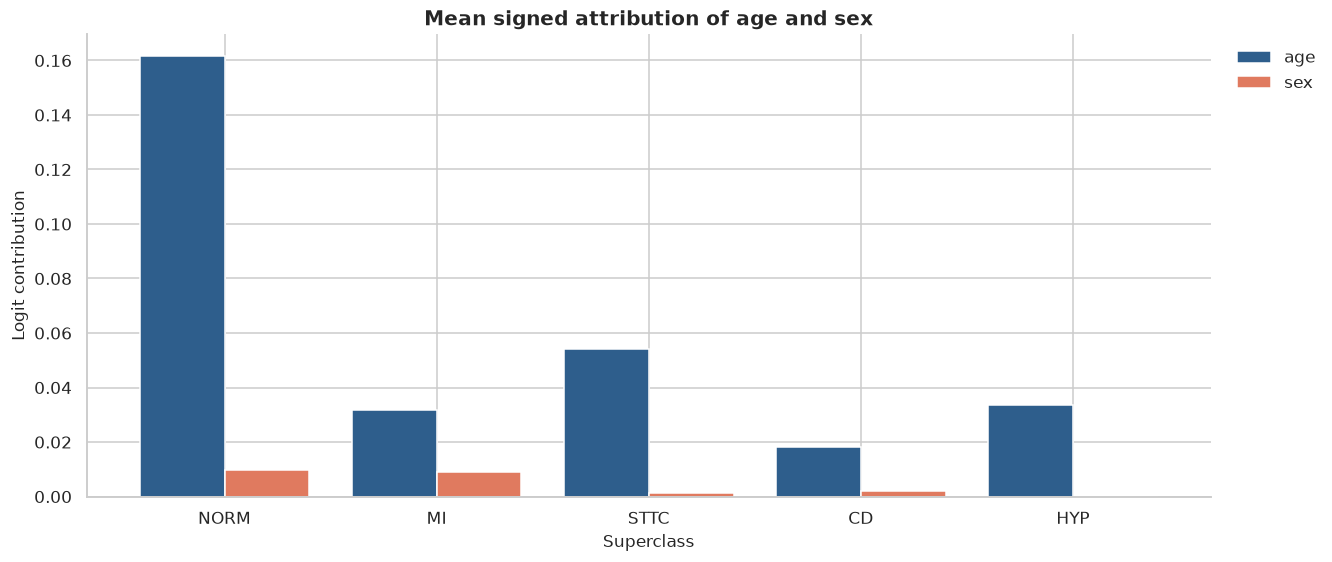

In [28]:
Charts.grouped_bar(metadata_contribution[list(METADATA_NAMES)], "Mean signed attribution of age and sex", "Superclass", "Logit contribution", colors=[PRIMARY_COLOR, SECONDARY_COLOR])

In [29]:
error_index = SUPERCLASSES.index(ERROR_CLASS)
missed_ids = selector.missed(ERROR_CLASS)
error_groups = {"true positive": selected_ids[ERROR_CLASS], "missed": missed_ids}
pd.DataFrame({
    group: {
        "records": len(ids),
        "median_probability": selector.probabilities.loc[ids, ERROR_CLASS].median(),
        "median_likelihood": selector.records.loc[ids, f"likelihood_{ERROR_CLASS}"].median(),
        "other_superclass_rate": selector.labels.loc[ids].drop(columns=ERROR_CLASS).any(axis=1).mean()
    }
    for group, ids in error_groups.items()
}).round(3)

,true positive,missed
records,100.000,154.000
median_probability,0.972,0.084
median_likelihood,100.000,50.000
other_superclass_rate,0.880,0.740


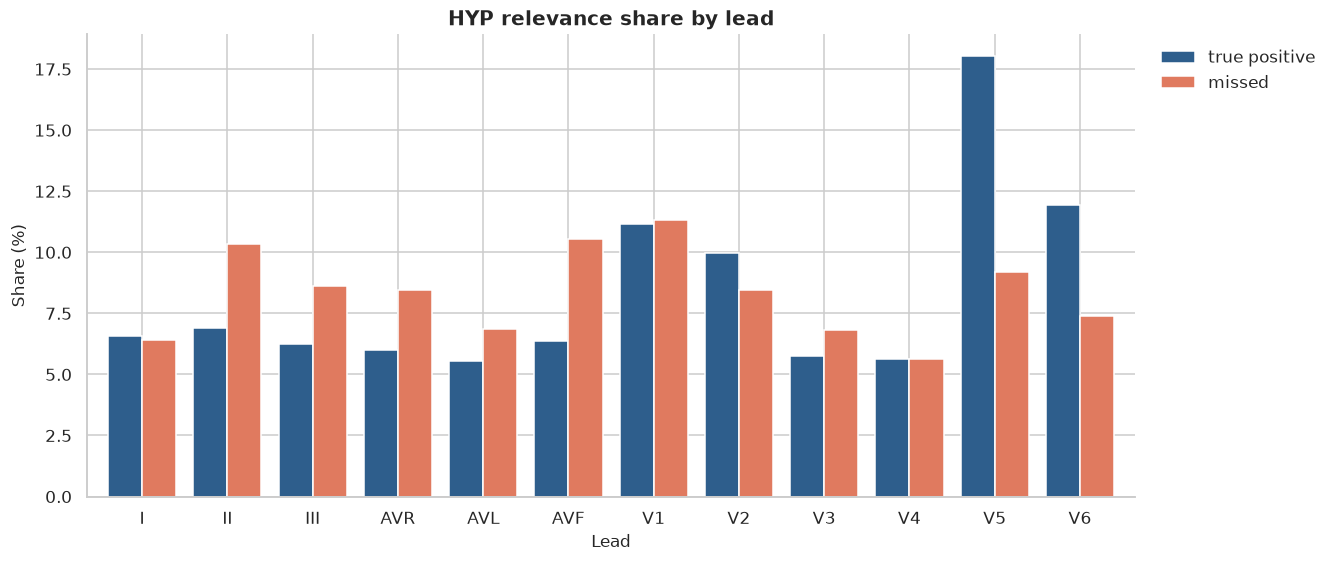

In [30]:
error_signals = {group: cohort.signals[cohort.rows(ids.tolist())].cpu().numpy() for group, ids in error_groups.items()}
error_relevance = {group: attribution.relevance(primary_method, cohort.rows(ids.tolist()), error_index).cpu().numpy() for group, ids in error_groups.items()}
error_matrices = {group: BeatProfile.relevance_matrix(error_relevance[group], error_signals[group]) for group in error_groups}
Charts.grouped_bar(BeatProfile.lead_shares(error_matrices).T, f"{ERROR_CLASS} relevance share by lead", "Lead", "Share (%)", colors=[PRIMARY_COLOR, SECONDARY_COLOR])

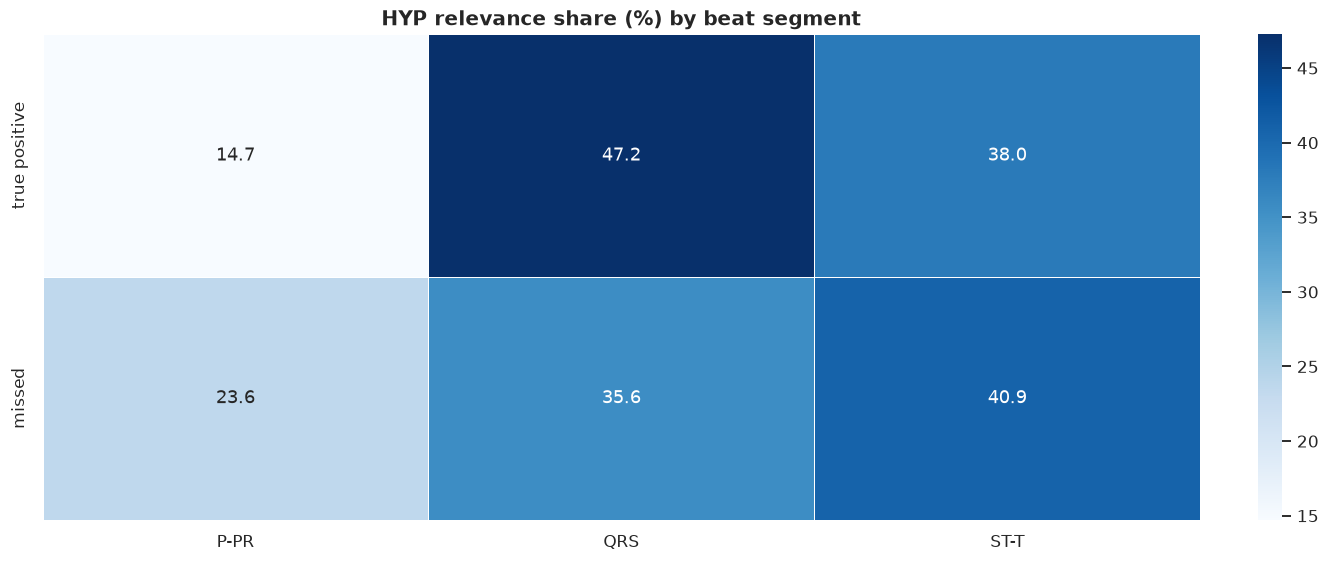

In [31]:
Charts.heatmap(pd.DataFrame({group: BeatProfile.segment_shares(matrix) for group, matrix in error_matrices.items()}).T, f"{ERROR_CLASS} relevance share (%) by beat segment", value_format=".1f", size=BASE_FIGURE_SIZE)